# Reto


# Reto: Física Computacional Avanzada

**Profesor:** Hernán Salinas

## 1. Definición de la distribución autorregresiva

### 1.1. Descripción del sistema físico

Consideramos el modelo de Ising bidimensional sobre una red cuadrada de $L\times L$ sitios. Cada sitio contiene un espín que puede tomar dos valores:

$$
s_i\in\{-1,+1\}.
$$

El número total de espines es:

$$
N=L^2.
$$

La energía de una configuración está determinada por el Hamiltoniano:

$$
E(s)=-J\sum_{\langle i,j\rangle}s_is_j-h\sum_i s_i,
$$

donde $J$ representa la intensidad de interacción entre primeros vecinos y $h$ corresponde al campo magnético externo.

En este trabajo utilizaremos las condiciones establecidas en el enunciado:

- Interacción ferromagnética: $J=1$.
- Campo magnético externo: $h=0$.
- Constante de Boltzmann: $k_B=1$.
- Condiciones periódicas de frontera.

A temperatura $T$, la distribución de equilibrio está dada por:

$$
p_B(s)=\frac{1}{Z}e^{-E(s)/T},
$$

donde $Z$ es la función de partición.

Nuestro objetivo es construir una distribución parametrizada $q_\theta(s)$ que aproxime la distribución de Boltzmann mediante un Transformer autorregresivo.

Para comenzar trabajaremos con $L=4$, correspondiente a $N=16$ espines y $2^{16}=65536$ configuraciones posibles. Este tamaño permitirá posteriormente comparar los resultados del modelo con una enumeración exacta.


In [ ]:

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ============================================================
# RETO DE FÍSICA COMPUTACIONAL AVANZADA
# PASO 1: DEFINICIÓN DEL TRANSFORMER AUTORREGRESIVO
# ============================================================

# Semillas para reproducibilidad
np.random.seed(42)
torch.manual_seed(42)

# Dispositivo de cálculo
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Parámetros del modelo de Ising
L = 4
N = L**2
J = 1.0
h = 0.0
T = 2.0
k_B = 1.0

# Representación de los espines mediante tokens
TOKEN_MENOS = 0
TOKEN_MAS = 1
TOKEN_BOS = 2

# Parámetros del Transformer
d_model = 32
n_heads = 4
n_layers = 2
d_ff = 64

print("Dispositivo:", device)
print("Tamaño de la red:", L, "x", L)
print("Número de espines:", N)
print("Configuraciones posibles:", 2**N)
print("Temperatura:", T)
print("Dimensión del embedding:", d_model)
print("Número de cabezas de atención:", n_heads)
print("Número de capas:", n_layers)


Dispositivo: cpu
Tamaño de la red: 4 x 4
Número de espines: 16
Configuraciones posibles: 65536
Temperatura: 2.0
Dimensión del embedding: 32
Número de cabezas de atención: 4
Número de capas: 2



### 1.2. Factorización autorregresiva de la distribución

Una configuración del modelo de Ising está formada por $N$ espines:

$$
s=(s_1,s_2,\ldots,s_N).
$$

Para representar su distribución de probabilidad utilizamos la regla de la cadena:

$$
\boxed{
q_\theta(s)=\prod_{i=1}^{N}q_\theta(s_i\mid s_{<i})
}
$$

donde:

$$
s_{<i}=(s_1,\ldots,s_{i-1}).
$$

Cada factor representa la probabilidad del espín $s_i$ condicionada a los espines anteriores.

La ventaja de esta representación es que permite construir una distribución conjunta normalizada a partir de probabilidades condicionales.

#### Representación mediante tokens

Los espines físicos se convierten en tokens:

| Espín físico | Token |
|---|---|
| $-1$ | 0 |
| $+1$ | 1 |
| Inicio de secuencia (BOS) | 2 |

Para una configuración de $N$ espines, la secuencia de entrada al Transformer será:

$$
(\mathrm{BOS},s_1,s_2,\ldots,s_{N-1}).
$$

Las salidas de la red corresponden a las predicciones de:

$$
(s_1,s_2,\ldots,s_N).
$$

De esta manera, cada predicción depende únicamente de los espines que la preceden.

Para garantizar esta propiedad utilizaremos una máscara causal, que impide que el mecanismo de atención acceda a información de posiciones futuras.


In [ ]:

# Configuración de ejemplo en una red 4x4
configuracion = np.array([
    [ 1, -1,  1,  1],
    [-1, -1,  1, -1],
    [ 1,  1, -1,  1],
    [-1,  1,  1, -1]
])

# Convertir la matriz en una secuencia
espines = configuracion.flatten()

# Conversión de espines {-1,+1} a tokens {0,1}
tokens = ((espines + 1) // 2).astype(int)

# Entrada desplazada
entrada = np.concatenate([
    [TOKEN_BOS],
    tokens[:-1]
])

print("Configuración original:")
print(configuracion)

print("\nSecuencia de espines:")
print(espines)

print("\nTokens:")
print(tokens)

print("\nEntrada al Transformer:")
print(entrada)

print("\nTokens que debe predecir:")
print(tokens)


Configuración original:
[[ 1 -1  1  1]
 [-1 -1  1 -1]
 [ 1  1 -1  1]
 [-1  1  1 -1]]

Secuencia de espines:
[ 1 -1  1  1 -1 -1  1 -1  1  1 -1  1 -1  1  1 -1]

Tokens:
[1 0 1 1 0 0 1 0 1 1 0 1 0 1 1 0]

Entrada al Transformer:
[2 1 0 1 1 0 0 1 0 1 1 0 1 0 1 1]

Tokens que debe predecir:
[1 0 1 1 0 0 1 0 1 1 0 1 0 1 1 0]



### 1.3. Arquitectura del Transformer autorregresivo

El Transformer será el modelo probabilístico encargado de calcular las distribuciones condicionales de los espines.

Su arquitectura contiene cuatro componentes principales.

**1. Embeddings de tokens**

Cada token se transforma en un vector de dimensión $d_{\mathrm{model}}$. Esta representación permite que la red procese los valores discretos de los espines.

**2. Embeddings posicionales**

Como los espines se ordenan siguiendo las filas de la red, incorporamos información sobre su posición en la secuencia. Esto permite distinguir entre diferentes sitios de la red.

**3. Atención causal**

El mecanismo de atención permite que cada posición utilice información de los tokens anteriores. La máscara causal impide que la predicción de $s_i$ dependa de espines futuros.

**4. Capa de salida y función softmax**

En cada posición, la red produce dos valores denominados logits:

$$
z_i=W_{\mathrm{out}}h_i+b.
$$

La función softmax convierte estos valores en probabilidades:

$$
q_\theta(s_i=a\mid s_{<i})
=
\frac{\exp(z_i^{(a)})}
{\exp(z_i^{(-1)})+\exp(z_i^{(+1)})},
$$

con $a\in\{-1,+1\}$.

Estas probabilidades cumplen:

$$
q_\theta(s_i=-1\mid s_{<i})
+
q_\theta(s_i=+1\mid s_{<i})
=1.
$$

Por tanto, el Transformer define una distribución condicional válida en cada posición de la secuencia.


In [ ]:

class TransformerIsing(nn.Module):

    def __init__(
        self,
        N,
        d_model=32,
        n_heads=4,
        n_layers=2,
        d_ff=64
    ):
        super().__init__()

        self.N = N
        self.bos_token = TOKEN_BOS

        # Embedding de los tres tokens
        self.token_embedding = nn.Embedding(
            num_embeddings=3,
            embedding_dim=d_model
        )

        # Embedding de las posiciones
        self.position_embedding = nn.Embedding(
            num_embeddings=N,
            embedding_dim=d_model
        )

        # Capa básica del Transformer
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_ff,
            dropout=0.0,
            batch_first=True,
            norm_first=True
        )

        # Bloques de atención
        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers,
            enable_nested_tensor=False
        )

        # Salida: dos logits por espín
        self.output_layer = nn.Linear(d_model, 2)

    def forward(self, tokens):

        batch_size, seq_len = tokens.shape

        if seq_len > self.N:
            raise ValueError(
                "La longitud supera el número de espines"
            )

        # Representación de los tokens
        emb_tokens = self.token_embedding(tokens)

        # Representación de las posiciones
        posiciones = torch.arange(
            seq_len,
            device=tokens.device
        )

        emb_posiciones = self.position_embedding(posiciones)

        # Combinar información de token y posición
        x = emb_tokens + emb_posiciones.unsqueeze(0)

        # Máscara causal
        mascara_causal = torch.triu(
            torch.ones(
                seq_len,
                seq_len,
                device=tokens.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        # Procesamiento por el Transformer
        x = self.transformer(
            x,
            mask=mascara_causal
        )

        # Obtener logits
        logits = self.output_layer(x)

        return logits



### 1.4. Verificación de la salida del Transformer

Antes de comenzar el entrenamiento, debemos comprobar que la arquitectura produce probabilidades válidas.

Para un lote de $M$ configuraciones de $N$ espines, el Transformer devuelve un tensor de dimensiones:

$$
(M,N,2).
$$

La última dimensión corresponde a los dos valores posibles del espín.

Al aplicar softmax, cada par de probabilidades debe sumar uno:

$$
\sum_{a\in\{-1,+1\}}
q_\theta(s_i=a\mid s_{<i})=1.
$$

Esta comprobación permite verificar el funcionamiento de la capa de salida y constituye una primera prueba de consistencia probabilística del modelo.

Es importante señalar que, en esta etapa, los parámetros de la red todavía no han sido entrenados. Por tanto, las probabilidades obtenidas no tienen por qué coincidir con la distribución de Boltzmann.


In [ ]:

# Crear el modelo
modelo = TransformerIsing(
    N=N,
    d_model=d_model,
    n_heads=n_heads,
    n_layers=n_layers,
    d_ff=d_ff
).to(device)

# Convertir la entrada anterior a tensor
entrada_tensor = torch.tensor(
    entrada,
    dtype=torch.long,
    device=device
).unsqueeze(0)

# Evaluación inicial
modelo.eval()

with torch.no_grad():

    logits = modelo(entrada_tensor)

    probabilidades = torch.softmax(
        logits,
        dim=-1
    )

print("Dimensiones de entrada:", entrada_tensor.shape)
print("Dimensiones de logits:", logits.shape)
print("Dimensiones de probabilidades:", probabilidades.shape)

print("\nProbabilidades del primer espín:")
print("P(s1 = -1):", probabilidades[0, 0, 0].item())
print("P(s1 = +1):", probabilidades[0, 0, 1].item())

# Verificar normalización de todas las posiciones
sumas = probabilidades.sum(dim=-1)

print("\n¿Todas las probabilidades suman uno?")
print(
    torch.allclose(
        sumas,
        torch.ones_like(sumas),
        atol=1e-6
    )
)

# Número de parámetros entrenables
n_parametros = sum(
    p.numel()
    for p in modelo.parameters()
    if p.requires_grad
)

print("\nParámetros entrenables:", n_parametros)


Dimensiones de entrada: torch.Size([1, 16])
Dimensiones de logits: torch.Size([1, 16, 2])
Dimensiones de probabilidades: torch.Size([1, 16, 2])

Probabilidades del primer espín:
P(s1 = -1): 0.20531471073627472
P(s1 = +1): 0.7946853041648865

¿Todas las probabilidades suman uno?
True

Parámetros entrenables: 17762



### 1.5. Cálculo del logaritmo de probabilidad de una configuración

La distribución autorregresiva está definida por:

$$
q_\theta(s)=
\prod_{i=1}^{N}q_\theta(s_i\mid s_{<i}).
$$

Aplicando el logaritmo:

$$
\boxed{
\ln q_\theta(s)=
\sum_{i=1}^{N}\ln q_\theta(s_i\mid s_{<i})
}
$$

Esta transformación convierte un producto de probabilidades en una suma de logaritmos, lo que facilita los cálculos numéricos y evita problemas de precisión cuando las probabilidades son muy pequeñas.

Para evaluar una configuración completa, realizamos una pasada del Transformer con la secuencia desplazada y seleccionamos, en cada posición, el logaritmo de probabilidad correspondiente al espín observado.

Esta cantidad será necesaria para estimar la energía libre variacional:

$$
F[q_\theta]
=
\langle E\rangle_{q_\theta}
+
T\langle\ln q_\theta(s)\rangle_{q_\theta},
$$

donde hemos utilizado unidades con $k_B=1$.

Durante el entrenamiento, el término energético favorecerá configuraciones de menor energía, mientras que el término entrópico contribuirá a mantener la diversidad estadística correspondiente a la temperatura del sistema.


In [ ]:

def log_probabilidad(modelo, espines):

    # Convertir espines {-1,+1} a tokens {0,1}
    tokens = ((espines + 1) // 2).long()

    batch_size = espines.shape[0]

    # Token BOS para cada configuración
    bos = torch.full(
        (batch_size, 1),
        TOKEN_BOS,
        dtype=torch.long,
        device=espines.device
    )

    # Secuencia desplazada
    entrada = torch.cat(
        [bos, tokens[:, :-1]],
        dim=1
    )

    # Logits del Transformer
    logits = modelo(entrada)

    # Logaritmos de probabilidades condicionales
    log_probs = F.log_softmax(
        logits,
        dim=-1
    )

    # Seleccionar las probabilidades observadas
    log_probs_observadas = torch.gather(
        log_probs,
        dim=2,
        index=tokens.unsqueeze(-1)
    ).squeeze(-1)

    # Sumar sobre todos los espines
    log_q = log_probs_observadas.sum(dim=1)

    return log_q


# Configuración de ejemplo
espines_tensor = torch.tensor(
    espines,
    dtype=torch.float32,
    device=device
).unsqueeze(0)

# Evaluar su probabilidad
with torch.no_grad():
    log_q = log_probabilidad(
        modelo,
        espines_tensor
    )

print("Log-probabilidad:")
print(log_q.item())

print("\nProbabilidad de la configuración:")
print(torch.exp(log_q).item())


Log-probabilidad:
-8.152488708496094

Probabilidad de la configuración:
0.00028801767621189356



### 1.6. Conclusión del primer paso

En esta primera etapa se construyó un Transformer autorregresivo para representar una distribución de probabilidad sobre las configuraciones del modelo de Ising bidimensional.

Se implementó la representación de espines mediante tokens, la incorporación de información posicional, el mecanismo de atención causal y la transformación de los logits en probabilidades condicionales.

También se verificó que las probabilidades producidas por la red están normalizadas en cada posición y se implementó una función para calcular el logaritmo de probabilidad de una configuración completa.

El resultado principal de esta etapa es disponer de un modelo probabilístico parametrizado $q_\theta(s)$, cuya estructura permite generar configuraciones secuencialmente y evaluar sus logaritmos de probabilidad.

En este punto, el Transformer todavía no reproduce necesariamente la distribución de Boltzmann, ya que sus parámetros permanecen sin entrenar. La aproximación al equilibrio estadístico se realizará posteriormente mediante la minimización variacional de la energía libre.



## 2. Inicialización del entrenamiento

### 2.1. Objetivo de la optimización

Una vez construido el Transformer autorregresivo, el siguiente paso consiste en preparar el procedimiento que permitirá ajustar sus parámetros para aproximar la distribución de equilibrio del modelo de Ising.

Recordemos que la distribución de Boltzmann está dada por:

$$
p_B(s)=\frac{1}{Z}e^{-E(s)/T},
$$

donde trabajamos en unidades con $k_B=1$.

De acuerdo con el principio variacional de Gibbs, buscamos minimizar la energía libre:

$$
\boxed{
F[q_\theta]
=
\langle E\rangle_{q_\theta}
+
T\langle\ln q_\theta(s)\rangle_{q_\theta}
}
$$

El gradiente respecto a los parámetros del Transformer es:

$$
\boxed{
\nabla_\theta F[q_\theta]
=
\left\langle
\left[E(s)+T\ln q_\theta(s)\right]
\nabla_\theta\ln q_\theta(s)
\right\rangle_{q_\theta}
}
$$

Esta expresión será utilizada posteriormente para actualizar los parámetros de la red neuronal.

### 2.2. Parámetros del entrenamiento

Para realizar la optimización necesitamos establecer cuatro elementos:

1. **Tamaño del lote ($M$):** número de configuraciones independientes generadas en cada iteración.
2. **Tasa de aprendizaje ($\eta$):** controla la magnitud de las actualizaciones de los parámetros.
3. **Número de iteraciones ($K$):** cantidad de veces que repetiremos el procedimiento de entrenamiento.
4. **Optimizador:** algoritmo encargado de modificar los parámetros del Transformer a partir del gradiente estimado.

Utilizaremos el optimizador Adam, que adapta las actualizaciones de los parámetros a partir de estimaciones de los momentos del gradiente.

Para una primera implementación seleccionaremos:

$$
M=128,\qquad
\eta=10^{-3},\qquad
K=500.
$$

Estos valores constituyen una configuración inicial de trabajo y podrán ajustarse dependiendo de la estabilidad del entrenamiento y de la calidad de los resultados.

En esta etapa únicamente inicializaremos el procedimiento. La generación de configuraciones y el cálculo de los gradientes se implementarán en los siguientes pasos.


In [ ]:

import torch
import torch.optim as optim

# ============================================================
# PASO 2: INICIALIZACIÓN DEL ENTRENAMIENTO
# ============================================================

# Parámetros del entrenamiento
M = 128                  # Tamaño del lote
K = 500                  # Número de iteraciones
eta = 1e-3               # Tasa de aprendizaje

# Configurar el modelo para entrenamiento
modelo.train()

# Inicializar el optimizador Adam
optimizador = optim.Adam(
    modelo.parameters(),
    lr=eta
)

# Estructuras para registrar los resultados
historial_energia_libre = []
historial_energia = []
historial_entropia = []
historial_gradiente = []

# Mostrar configuración
print("=" * 55)
print("INICIALIZACIÓN DEL ENTRENAMIENTO")
print("=" * 55)

print(f"Tamaño de la red:       {L} x {L}")
print(f"Número de espines:      {N}")
print(f"Temperatura:            {T}")
print(f"Tamaño del lote:        {M}")
print(f"Tasa de aprendizaje:    {eta}")
print(f"Número de iteraciones:  {K}")
print(f"Optimizador:            Adam")
print(f"Dispositivo:            {device}")

print("=" * 55)
print("Optimizador inicializado correctamente.")


INICIALIZACIÓN DEL ENTRENAMIENTO
Tamaño de la red:       4 x 4
Número de espines:      16
Temperatura:            2.0
Tamaño del lote:        128
Tasa de aprendizaje:    0.001
Número de iteraciones:  500
Optimizador:            Adam
Dispositivo:            cpu
Optimizador inicializado correctamente.



### 2.3. Interpretación de los hiperparámetros

La elección de los hiperparámetros influye en el comportamiento numérico del entrenamiento.

**Tamaño del lote**

En cada iteración se generarán $M=128$ configuraciones independientes del sistema. Estas muestras se utilizarán para estimar la energía libre y su gradiente.

Un lote más grande puede reducir las fluctuaciones estadísticas del estimador, aunque también incrementa el costo computacional.

**Tasa de aprendizaje**

La tasa $\eta=10^{-3}$ determina la escala de las actualizaciones realizadas por Adam. Un valor demasiado grande puede producir inestabilidad, mientras que uno demasiado pequeño puede hacer que el entrenamiento avance lentamente.

**Número de iteraciones**

Inicialmente utilizaremos $K=500$ iteraciones. Esto no garantiza que el modelo alcance la distribución de equilibrio, por lo que será necesario analizar la evolución de la energía libre y comparar las propiedades físicas obtenidas con los resultados exactos.

**Temperatura**

Mantendremos la temperatura fija en $T=2.0$, como se estableció en el primer paso.

La temperatura determina la importancia relativa de la energía y la entropía en la función variacional:

$$
F[q_\theta]
=
\langle E\rangle_{q_\theta}
-
T S[q_\theta].
$$

A temperaturas bajas, las configuraciones de menor energía adquieren mayor importancia. A temperaturas altas, el término entrópico favorece una mayor diversidad de configuraciones.

El objetivo del entrenamiento será encontrar una distribución que represente correctamente el equilibrio entre ambos efectos.


In [ ]:

# ============================================================
# VERIFICACIÓN DEL MODELO Y DEL OPTIMIZADOR
# ============================================================

# Número total de parámetros
parametros_totales = sum(
    p.numel() for p in modelo.parameters()
)

# Número de parámetros entrenables
parametros_entrenables = sum(
    p.numel()
    for p in modelo.parameters()
    if p.requires_grad
)

# Parámetros incluidos en Adam
parametros_adam = sum(
    p.numel()
    for grupo in optimizador.param_groups
    for p in grupo["params"]
)

print("VERIFICACIÓN DE PARÁMETROS")
print("-" * 45)

print(f"Parámetros totales:       {parametros_totales}")
print(f"Parámetros entrenables:   {parametros_entrenables}")
print(f"Parámetros en Adam:       {parametros_adam}")

print("-" * 45)

if (
    parametros_entrenables > 0
    and parametros_entrenables == parametros_adam
):
    print("Verificación correcta.")
    print("Adam reconoce todos los parámetros entrenables.")
else:
    print("Revisar la configuración del optimizador.")


VERIFICACIÓN DE PARÁMETROS
---------------------------------------------
Parámetros totales:       17762
Parámetros entrenables:   17762
Parámetros en Adam:       17762
---------------------------------------------
Verificación correcta.
Adam reconoce todos los parámetros entrenables.



### 2.4. Conclusión del segundo paso

En esta etapa se preparó el procedimiento de optimización del Transformer autorregresivo mediante el algoritmo Adam.

Se definieron el tamaño del lote, la tasa de aprendizaje y el número de iteraciones. Además, se crearon las estructuras necesarias para registrar la evolución de la energía libre, la energía media, la entropía y la magnitud del gradiente durante el entrenamiento.

También se verificó que los parámetros entrenables del modelo están correctamente incorporados al optimizador.

Con esto queda preparada la infraestructura del entrenamiento variacional. Sin embargo, todavía no se han generado configuraciones ni se han realizado actualizaciones de los parámetros.

El siguiente paso consistirá en implementar el muestreo autorregresivo, mediante el cual el Transformer generará configuraciones completas del modelo de Ising a partir de sus probabilidades condicionales.



## 3. Generación de un lote de configuraciones

### 3.1. Fundamento del muestreo autorregresivo

Una vez definido el Transformer, necesitamos utilizarlo para generar configuraciones del sistema de Ising.

Recordemos que la distribución del modelo se expresa mediante:

$$
q_\theta(s)=\prod_{i=1}^{N}q_\theta(s_i\mid s_{<i}),
$$

donde $s_{<i}$ representa los espines anteriores al sitio $i$.

El objetivo de esta etapa es generar un lote de $M$ configuraciones independientes:

$$
s^{(1)},s^{(2)},\ldots,s^{(M)}\sim q_\theta.
$$

Para construir cada configuración seguimos un procedimiento secuencial:

1. Comenzamos con el token de inicio BOS.
2. El Transformer calcula las probabilidades de los valores $-1$ y $+1$ para el primer espín.
3. Muestreamos uno de los dos valores según las probabilidades obtenidas.
4. Añadimos el espín generado a la secuencia.
5. Repetimos el procedimiento hasta completar los $N$ espines.

En cada posición se calcula:

$$
q_\theta(s_i=a\mid s_{<i})
=
\frac{\exp(z_i^{(a)})}
{\exp(z_i^{(-1)})+\exp(z_i^{(+1)})},
$$

con $a\in\{-1,+1\}$.

El muestreo se realiza sin construir un grafo de diferenciación automática, ya que en esta etapa solamente necesitamos generar configuraciones. Posteriormente, sus logaritmos de probabilidad se evaluarán nuevamente para calcular el gradiente variacional.

Es importante señalar que las configuraciones generadas inicialmente no tienen por qué representar el equilibrio del modelo de Ising. El Transformer todavía no ha sido entrenado.


In [ ]:

# ============================================================
# PASO 3: MUESTREO AUTORREGRESIVO
# ============================================================

@torch.no_grad()
def generar_configuraciones(modelo, M, N, device):

    # Iniciar cada secuencia con el token BOS
    secuencias = torch.full(
        (M, 1),
        TOKEN_BOS,
        dtype=torch.long,
        device=device
    )

    # Generar los espines uno por uno
    for i in range(N):

        # Calcular logits para la secuencia disponible
        logits = modelo(secuencias)

        # Utilizar la última posición para predecir s_i
        logits_siguiente = logits[:, -1, :]

        # Convertir logits en probabilidades
        probabilidades = torch.softmax(
            logits_siguiente,
            dim=-1
        )

        # Muestrear el siguiente token
        siguiente_token = torch.multinomial(
            probabilidades,
            num_samples=1
        )

        # Añadir el nuevo token a la secuencia
        if i < N - 1:
            secuencias = torch.cat(
                [secuencias, siguiente_token],
                dim=1
            )
        else:
            ultimo_token = siguiente_token

    # Eliminar BOS y añadir el último token generado
    tokens = torch.cat(
        [secuencias[:, 1:], ultimo_token],
        dim=1
    )

    # Convertir tokens {0,1} a espines {-1,+1}
    espines = 2 * tokens - 1

    return espines



### 3.2. Representación de las configuraciones generadas

El Transformer genera cada configuración como una secuencia de $N=L^2$ espines:

$$
s^{(m)}=(s_1^{(m)},s_2^{(m)},\ldots,s_N^{(m)}).
$$

Para recuperar la geometría del modelo de Ising bidimensional, reorganizamos cada secuencia como una matriz de $L\times L$:

$$
s^{(m)}=
\begin{pmatrix}
s_{1,1} & s_{1,2} & \cdots & s_{1,L}\\
s_{2,1} & s_{2,2} & \cdots & s_{2,L}\\
\vdots & \vdots & \ddots & \vdots\\
s_{L,1} & s_{L,2} & \cdots & s_{L,L}
\end{pmatrix}.
$$

Para nuestro caso, $L=4$ y $N=16$.

Generaremos un lote de $M=128$ configuraciones y verificaremos que:

- Cada configuración contiene exactamente 16 espines.
- Los valores pertenecen al conjunto $\{-1,+1\}$.
- Las configuraciones pueden reorganizarse como matrices de $4\times4$.
- El modelo produce muestras diferentes debido al carácter probabilístico del muestreo.

La independencia entre muestras se obtiene utilizando sorteos aleatorios independientes para cada secuencia, condicionados a los parámetros fijos del Transformer.


In [ ]:

# ============================================================
# GENERACIÓN DEL LOTE DE CONFIGURACIONES
# ============================================================

# El muestreo no requiere gradientes
modelo.eval()

# Generar M configuraciones
configuraciones = generar_configuraciones(
    modelo=modelo,
    M=M,
    N=N,
    device=device
)

# Dimensiones del lote
print("Dimensiones del lote:")
print(configuraciones.shape)

# Valores posibles
valores = torch.unique(configuraciones)

print("\nValores de espín encontrados:")
print(valores.cpu().numpy())

# Verificar dimensiones
dimensiones_correctas = (
    configuraciones.shape == (M, N)
)

# Verificar que solo existen espines -1 y +1
espines_validos = torch.all(
    (configuraciones == -1) |
    (configuraciones == 1)
).item()

print("\nVerificación de dimensiones:", dimensiones_correctas)
print("Verificación de espines:", espines_validos)

# Recuperar la estructura bidimensional
redes = configuraciones.reshape(M, L, L)

print("\nDimensiones de las redes:")
print(redes.shape)

print("\nPrimera configuración generada:")
print(redes[0].cpu().numpy())

# Cantidad de configuraciones diferentes
n_unicas = torch.unique(
    configuraciones,
    dim=0
).shape[0]

print("\nConfiguraciones distintas:", n_unicas)
print("Total de configuraciones:", M)


Dimensiones del lote:
torch.Size([128, 16])

Valores de espín encontrados:
[-1  1]

Verificación de dimensiones: True
Verificación de espines: True

Dimensiones de las redes:
torch.Size([128, 4, 4])

Primera configuración generada:
[[ 1 -1 -1 -1]
 [-1 -1  1 -1]
 [ 1  1  1 -1]
 [-1  1 -1 -1]]

Configuraciones distintas: 127
Total de configuraciones: 128



### 3.3. Visualización de las configuraciones de Ising

Para interpretar físicamente las muestras generadas, representaremos algunas configuraciones como matrices de colores.

Cada celda de la matriz corresponde a un espín:

- El color azul representa $s_i=-1$.
- El color rojo representa $s_i=+1$.

Esta visualización permite identificar la orientación de los espines y observar la estructura espacial de las configuraciones.

En un sistema ferromagnético, las configuraciones de baja energía tienden a presentar regiones de espines alineados. Sin embargo, en esta etapa el Transformer todavía no ha sido entrenado con el Hamiltoniano de Ising.

Por tanto, las configuraciones generadas constituyen muestras de la distribución inicial $q_\theta(s)$, no necesariamente de la distribución de Boltzmann.

Más adelante, después del entrenamiento, podremos comparar estas configuraciones iniciales con las producidas por el modelo optimizado.


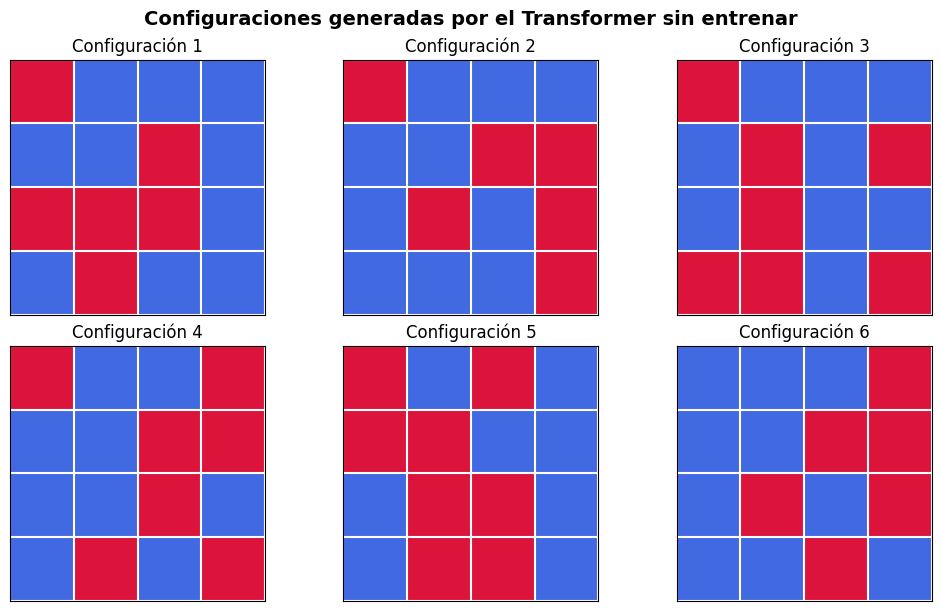

In [ ]:

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

# ============================================================
# VISUALIZACIÓN DE CONFIGURACIONES GENERADAS
# ============================================================

# Convertir seis configuraciones a NumPy
muestras = redes[:6].cpu().numpy()

# Mapa de colores: azul (-1), rojo (+1)
cmap = ListedColormap(["royalblue", "crimson"])
norm = BoundaryNorm([-1.5, 0, 1.5], cmap.N)

fig, axes = plt.subplots(
    2, 3,
    figsize=(10, 6),
    constrained_layout=True
)

for i, ax in enumerate(axes.flat):

    ax.imshow(
        muestras[i],
        cmap=cmap,
        norm=norm,
        interpolation="nearest"
    )

    ax.set_title(f"Configuración {i + 1}")

    ax.set_xticks(range(L))
    ax.set_yticks(range(L))

    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.set_xticks(
        np.arange(-0.5, L, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, L, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="white",
        linewidth=1.5
    )

    ax.tick_params(
        which="both",
        length=0
    )

fig.suptitle(
    "Configuraciones generadas por el Transformer sin entrenar",
    fontsize=14,
    fontweight="bold"
)

plt.show()



### 3.4. Conclusión del tercer paso

En esta etapa se implementó el procedimiento de muestreo autorregresivo del Transformer para generar configuraciones del modelo de Ising bidimensional.

La generación se realizó de manera secuencial, comenzando con el token BOS y seleccionando cada espín a partir de las probabilidades condicionales calculadas por la red neuronal.

Se verificó que las configuraciones obtenidas contienen el número correcto de espines y que todos sus valores pertenecen al conjunto $\{-1,+1\}$.

También se recuperó la estructura bidimensional de la red y se visualizaron algunas configuraciones generadas.

El resultado principal es disponer de una función capaz de producir lotes de configuraciones independientes según la distribución $q_\theta(s)$ definida por el Transformer.

Es importante señalar que, hasta este punto, el modelo no ha sido entrenado para reproducir el equilibrio estadístico del sistema. Las configuraciones actuales servirán como punto de partida para el proceso de optimización variacional.

En el siguiente paso calcularemos la energía de cada configuración utilizando el Hamiltoniano de Ising con condiciones periódicas de frontera y evaluaremos su logaritmo de probabilidad mediante el Transformer.



## 4. Evaluación de la energía y la probabilidad

### 4.1. Hamiltoniano del modelo de Ising bidimensional

Una vez generado un lote de configuraciones mediante el Transformer, necesitamos calcular la energía correspondiente a cada una.

Consideramos el modelo de Ising ferromagnético sobre una red cuadrada de $L\times L$ espines, descrito por el Hamiltoniano:

$$
E(s)=-J\sum_{\langle i,j\rangle}s_is_j-h\sum_i s_i.
$$

En nuestro caso utilizamos:

$$
J=1,\qquad h=0,\qquad L=4.
$$

Por tanto, la energía depende únicamente de las interacciones entre primeros vecinos:

$$
E(s)=-\sum_{\langle i,j\rangle}s_is_j.
$$

Para implementar las condiciones periódicas de frontera, el Hamiltoniano puede escribirse como:

$$
\boxed{
E(s)=-J\sum_{x=0}^{L-1}\sum_{y=0}^{L-1}
s_{x,y}\left(s_{(x+1)\bmod L,y}
+s_{x,(y+1)\bmod L}\right)
-h\sum_{x,y}s_{x,y}
}
$$

La operación módulo permite conectar los espines situados en los bordes opuestos de la red.

Por ejemplo, el vecino derecho del último espín de una fila es el primero de esa misma fila.

Para evitar contar dos veces las interacciones, únicamente consideramos los vecinos situados hacia la derecha y hacia abajo.

En una red cuadrada de $L\times L$ con condiciones periódicas y $L\geq3$, existen $2L^2$ enlaces de primeros vecinos.

Para $L=4$:

$$
N_{\mathrm{enlaces}}=2(4^2)=32.
$$

En consecuencia, cuando todos los espines están alineados, cada producto entre vecinos es igual a $+1$ y la energía alcanza su valor mínimo:

$$
\boxed{E_{\min}=-32}
$$

Este resultado servirá para verificar que nuestra implementación del Hamiltoniano es correcta.


In [ ]:

# ============================================================
# PASO 4: ENERGÍA DEL MODELO DE ISING BIDIMENSIONAL
# ============================================================

def energia_ising(configuraciones, L, J=1.0, h=0.0):

    # Número de configuraciones del lote
    M_actual = configuraciones.shape[0]

    # Recuperar la geometría bidimensional
    espines = configuraciones.reshape(M_actual, L, L)

    # Vecinos en la dirección vertical
    vecinos_abajo = torch.roll(
        espines,
        shifts=-1,
        dims=1
    )

    # Vecinos en la dirección horizontal
    vecinos_derecha = torch.roll(
        espines,
        shifts=-1,
        dims=2
    )

    # Energía de interacción
    energia_interaccion = -J * (
        espines * vecinos_abajo
        + espines * vecinos_derecha
    ).sum(dim=(1, 2))

    # Energía asociada al campo externo
    energia_campo = -h * espines.sum(dim=(1, 2))

    # Energía total de cada configuración
    energia_total = energia_interaccion + energia_campo

    return energia_total



### 4.2. Verificación del cálculo de la energía

Antes de evaluar las configuraciones generadas por el Transformer, comprobaremos el Hamiltoniano utilizando configuraciones cuyo resultado conocemos analíticamente.

**Caso 1. Todos los espines alineados**

Si todos los espines tienen el mismo valor, cada interacción entre primeros vecinos contribuye con $-J$.

Para una red de $4\times4$ y $J=1$:

$$
E=-32.
$$

Este resultado se obtiene tanto para la configuración con todos los espines $+1$ como para aquella con todos los espines $-1$, debido a que el campo externo es cero.

**Caso 2. Configuración alternada**

Consideremos una configuración en forma de tablero de ajedrez, donde cada espín tiene orientación opuesta a sus vecinos.

En este caso:

$$
s_is_j=-1
$$

para todos los pares de primeros vecinos.

Por tanto:

$$
E=+32.
$$

Estos dos casos representan los valores extremos de energía para el sistema considerado.

La comparación con estos resultados permite comprobar el tratamiento de las condiciones periódicas y el conteo de las interacciones.


In [ ]:

# ============================================================
# VERIFICACIÓN DEL HAMILTONIANO
# ============================================================

# Todos los espines hacia arriba
todos_arriba = torch.ones(
    (1, N),
    dtype=torch.long,
    device=device
)

# Todos los espines hacia abajo
todos_abajo = -torch.ones(
    (1, N),
    dtype=torch.long,
    device=device
)

# Configuración alternada tipo tablero de ajedrez
filas, columnas = torch.meshgrid(
    torch.arange(L, device=device),
    torch.arange(L, device=device),
    indexing="ij"
)

tablero = (-1) ** (filas + columnas)
tablero = tablero.reshape(1, N)

# Calcular las energías
E_arriba = energia_ising(todos_arriba, L, J, h)
E_abajo = energia_ising(todos_abajo, L, J, h)
E_tablero = energia_ising(tablero, L, J, h)

print("VERIFICACIÓN DEL HAMILTONIANO")
print("-" * 45)

print(f"Todos los espines +1: {E_arriba.item():.1f}")
print(f"Todos los espines -1: {E_abajo.item():.1f}")
print(f"Configuración alternada: {E_tablero.item():.1f}")

# Comprobaciones automáticas
assert np.isclose(E_arriba.item(), -32)
assert np.isclose(E_abajo.item(), -32)
assert np.isclose(E_tablero.item(), 32)

print("\nLas tres verificaciones son correctas.")


VERIFICACIÓN DEL HAMILTONIANO
---------------------------------------------
Todos los espines +1: -32.0
Todos los espines -1: -32.0
Configuración alternada: 32.0

Las tres verificaciones son correctas.



### 4.3. Energía de las configuraciones generadas

Una vez verificado el Hamiltoniano, calcularemos la energía de las configuraciones producidas por el Transformer.

Si generamos un lote de $M$ configuraciones:

$$
s^{(1)},s^{(2)},\ldots,s^{(M)}\sim q_\theta,
$$

obtendremos un conjunto de energías:

$$
E_1,E_2,\ldots,E_M.
$$

La energía media del lote se estima mediante:

$$
\boxed{
\widehat{\langle E\rangle}
=
\frac{1}{M}\sum_{m=1}^{M}E_m
}
$$

También calcularemos la energía media por espín:

$$
\boxed{
\widehat e=\frac{\widehat{\langle E\rangle}}{N}
}
$$

Esta última magnitud permite comparar sistemas de diferentes tamaños.

Para nuestro sistema de $N=16$ espines, la energía mínima por espín es:

$$
e_{\min}=\frac{-32}{16}=-2.
$$

Debemos recordar que el Transformer todavía no ha sido entrenado. Por tanto, la energía media inicial no tiene por qué coincidir con la energía de equilibrio del modelo de Ising.

Su valor servirá como referencia para analizar los cambios producidos durante el entrenamiento.


In [ ]:

# ============================================================
# ENERGÍAS DE LAS CONFIGURACIONES GENERADAS
# ============================================================

# Calcular energía de cada configuración
energias = energia_ising(
    configuraciones,
    L=L,
    J=J,
    h=h
)

# Energía media del lote
energia_media = energias.float().mean()

# Energía media por espín
energia_por_espin = energia_media / N

print("RESULTADOS ENERGÉTICOS")
print("-" * 45)

print("Número de configuraciones:", len(energias))

print(f"Energía media: {energia_media.item():.4f}")

print(f"Energía media por espín: {energia_por_espin.item():.4f}")

print(f"Energía mínima observada: {energias.min().item():.1f}")

print(f"Energía máxima observada: {energias.max().item():.1f}")

print("\nEnergías de las primeras 10 configuraciones:")
print(energias[:10].cpu().numpy())


RESULTADOS ENERGÉTICOS
---------------------------------------------
Número de configuraciones: 128
Energía media: 2.6562
Energía media por espín: 0.1660
Energía mínima observada: -12.0
Energía máxima observada: 16.0

Energías de las primeras 10 configuraciones:
[ 0.  4.  4.  4. -0.  4. -4. -0.  4. -0.]



### 4.4. Logaritmo de probabilidad de las configuraciones

Además de la energía, necesitamos conocer la probabilidad que el Transformer asigna a cada configuración.

La distribución autorregresiva se expresa como:

$$
q_\theta(s)=
\prod_{i=1}^{N}q_\theta(s_i\mid s_{<i}).
$$

Por tanto, el logaritmo de probabilidad es:

$$
\boxed{
\ell_m=\ln q_\theta(s^{(m)})
=
\sum_{i=1}^{N}
\ln q_\theta(s_i^{(m)}\mid s_{<i}^{(m)})
}
$$

En el paso 1 implementamos la función `log_probabilidad()`, que realiza precisamente este cálculo.

Es importante distinguir entre las dos cantidades:

- La energía $E_m$ depende del Hamiltoniano físico del modelo de Ising.
- El logaritmo $\ell_m$ depende de las probabilidades que asigna el Transformer.

Durante el entrenamiento, ambas cantidades se combinarán para construir el estimador de energía libre:

$$
f_m=E_m+T\ell_m.
$$

La energía libre variacional estimada será:

$$
\widehat F_\theta=
\frac{1}{M}\sum_{m=1}^{M}f_m.
$$

En esta etapa solamente calcularemos las energías y los logaritmos de probabilidad. La estimación y minimización de la energía libre se desarrollarán en los siguientes pasos.


In [ ]:

# ============================================================
# LOGARITMOS DE PROBABILIDAD DEL LOTE
# ============================================================

# Evaluación sin actualizar parámetros
modelo.eval()

with torch.no_grad():

    log_q = log_probabilidad(
        modelo,
        configuraciones
    )

    probabilidades = torch.exp(log_q)

print("EVALUACIÓN PROBABILÍSTICA")
print("-" * 50)

print("Dimensiones de log_q:", log_q.shape)

print("\nPrimeras cinco configuraciones:")
print()

for i in range(5):

    print(
        f"Configuración {i+1}: "
        f"E = {energias[i].item():6.1f} | "
        f"log q = {log_q[i].item():9.4f} | "
        f"q = {probabilidades[i].item():.8f}"
    )

# Verificaciones
assert torch.isfinite(log_q).all()
assert (probabilidades >= 0).all()
assert (probabilidades <= 1).all()

print("\nLos logaritmos de probabilidad son finitos.")
print("Las probabilidades calculadas son válidas.")


EVALUACIÓN PROBABILÍSTICA
--------------------------------------------------
Dimensiones de log_q: torch.Size([128])

Primeras cinco configuraciones:

Configuración 1: E =    0.0 | log q =   -8.5610 | q = 0.00019143
Configuración 2: E =    4.0 | log q =   -8.5435 | q = 0.00019480
Configuración 3: E =    4.0 | log q =  -10.0892 | q = 0.00004153
Configuración 4: E =    4.0 | log q =   -9.8371 | q = 0.00005343
Configuración 5: E =   -0.0 | log q =   -9.7893 | q = 0.00005605

Los logaritmos de probabilidad son finitos.
Las probabilidades calculadas son válidas.



### 4.5. Interpretación física y probabilística

En este paso calculamos las dos cantidades necesarias para evaluar el principio variacional de Gibbs: la energía física de cada configuración y su logaritmo de probabilidad bajo el Transformer.

La energía se obtuvo a partir del Hamiltoniano de Ising con condiciones periódicas de frontera, mientras que el logaritmo de probabilidad se calculó mediante la factorización autorregresiva.

Estas cantidades tienen funciones diferentes dentro del entrenamiento.

El término energético favorece las configuraciones con espines alineados, debido a la interacción ferromagnética.

Por su parte, el término asociado a $\ln q_\theta(s)$ permite incorporar la contribución entrópica de la distribución generada por el modelo.

La combinación de ambos términos permitirá construir la energía libre:

$$
F[q_\theta]
=
\langle E\rangle_{q_\theta}
+
T\langle\ln q_\theta(s)\rangle_{q_\theta}.
$$

El objetivo del entrenamiento no será únicamente encontrar configuraciones de energía mínima, sino reproducir la distribución de equilibrio correspondiente a la temperatura seleccionada.

Esta distinción es importante porque, a temperatura finita, el sistema puede ocupar configuraciones excitadas con probabilidades determinadas por el factor de Boltzmann.


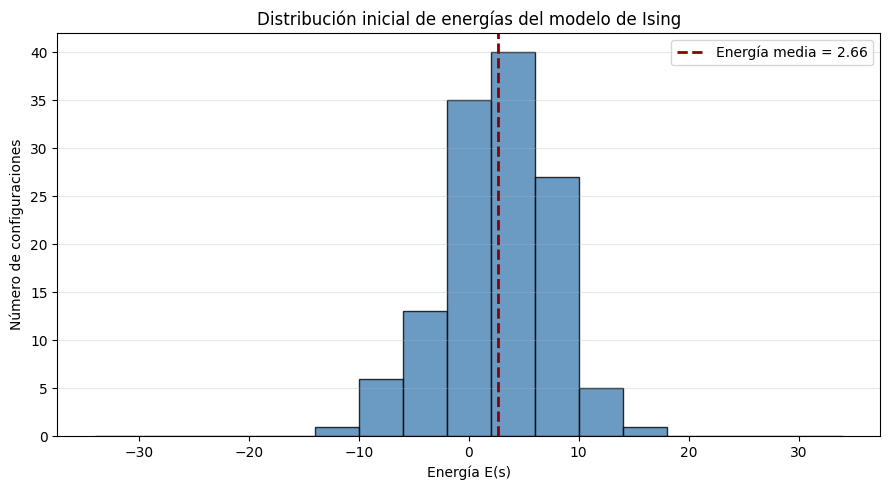

In [ ]:

# ============================================================
# HISTOGRAMA DE ENERGÍAS DEL LOTE INICIAL
# ============================================================

energias_numpy = energias.detach().cpu().numpy()

plt.figure(figsize=(9, 5))

plt.hist(
    energias_numpy,
    bins=np.arange(-34, 38, 4),
    color="steelblue",
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    energia_media.item(),
    color="darkred",
    linestyle="--",
    linewidth=2,
    label=f"Energía media = {energia_media.item():.2f}"
)

plt.xlabel("Energía E(s)")
plt.ylabel("Número de configuraciones")
plt.title("Distribución inicial de energías del modelo de Ising")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### 4.6. Conclusión del cuarto paso

En esta etapa se implementó el Hamiltoniano del modelo de Ising bidimensional con interacción ferromagnética y condiciones periódicas de frontera.

La implementación se verificó utilizando configuraciones conocidas, obteniendo una energía de $-32$ para los estados completamente alineados y de $+32$ para la configuración alternada.

Posteriormente, se calcularon las energías de las configuraciones generadas por el Transformer y se estimó la energía media del lote, tanto en valores totales como por espín.

También se evaluaron los logaritmos de probabilidad de las configuraciones mediante la función autorregresiva construida anteriormente.

De esta manera, para cada configuración disponemos de dos cantidades:

$$
E_m=E(s^{(m)}),
\qquad
\ell_m=\ln q_\theta(s^{(m)}).
$$

Estas magnitudes constituyen la información necesaria para estimar la energía libre variacional y, posteriormente, calcular el gradiente que permitirá entrenar el Transformer.

El siguiente paso consistirá en construir el estimador de energía libre, junto con las estimaciones de energía media y entropía, siguiendo el principio variacional de Gibbs.



## 5. Estimación de la energía libre variacional

### 5.1. Fundamento termodinámico

En los pasos anteriores construimos un Transformer autorregresivo capaz de generar configuraciones del modelo de Ising y calcular tanto su energía como su logaritmo de probabilidad.

El siguiente objetivo consiste en utilizar estas cantidades para estimar la energía libre variacional.

En mecánica estadística, la energía libre de Helmholtz se define como:

$$
F=U-TS,
$$

donde:

- $U$ es la energía interna.
- $T$ es la temperatura absoluta.
- $S$ es la entropía.

Para una distribución de probabilidad $q_\theta(s)$, la energía interna está dada por:

$$
U[q_\theta]=\sum_s q_\theta(s)E(s).
$$

La entropía de Gibbs, en unidades con $k_B=1$, es:

$$
S[q_\theta]=-\sum_s q_\theta(s)\ln q_\theta(s).
$$

Sustituyendo estas expresiones en la definición de energía libre:

$$
F[q_\theta]
=
\sum_s q_\theta(s)E(s)
+
T\sum_s q_\theta(s)\ln q_\theta(s).
$$

Por tanto:

$$
\boxed{
F[q_\theta]
=
\left\langle E(s)+T\ln q_\theta(s)\right\rangle_{q_\theta}
}
$$

Esta expresión constituye la función variacional que minimizaremos durante el entrenamiento del Transformer.

De acuerdo con el principio variacional de Gibbs:

$$
F[q_\theta]\geq F_B,
$$

donde $F_B=-T\ln Z$ es la energía libre exacta de equilibrio.

La igualdad se alcanza cuando:

$$
q_\theta(s)=p_B(s).
$$

En consecuencia, minimizar la energía libre variacional permite aproximar la distribución de Boltzmann del sistema de Ising.


In [ ]:

# ============================================================
# PASO 5: ESTIMACIÓN DE LA ENERGÍA LIBRE VARIACIONAL
# ============================================================

# Energías y log-probabilidades del lote
E_m = energias.float()
ell_m = log_q

# Contribución de cada configuración
f_m = E_m + T * ell_m

# Estimador Monte Carlo de energía libre
F_estimada = f_m.mean()

# Energía libre estimada por espín
F_por_espin = F_estimada / N

print("=" * 55)
print("ESTIMACIÓN DE LA ENERGÍA LIBRE")
print("=" * 55)

print(f"Número de configuraciones: {len(f_m)}")
print(f"Temperatura: {T:.4f}")

print(f"\nEnergía libre estimada: {F_estimada.item():.6f}")
print(f"Energía libre por espín: {F_por_espin.item():.6f}")

print("\nPrimeras cinco contribuciones f_m:")

for i in range(5):
    print(
        f"Configuración {i+1}: "
        f"E = {E_m[i].item():7.3f} | "
        f"log q = {ell_m[i].item():9.4f} | "
        f"f = {f_m[i].item():9.4f}"
    )


ESTIMACIÓN DE LA ENERGÍA LIBRE
Número de configuraciones: 128
Temperatura: 2.0000

Energía libre estimada: -16.360867
Energía libre por espín: -1.022554

Primeras cinco contribuciones f_m:
Configuración 1: E =   0.000 | log q =   -8.5610 | f =  -17.1219
Configuración 2: E =   4.000 | log q =   -8.5435 | f =  -13.0871
Configuración 3: E =   4.000 | log q =  -10.0892 | f =  -16.1784
Configuración 4: E =   4.000 | log q =   -9.8371 | f =  -15.6743
Configuración 5: E =  -0.000 | log q =   -9.7893 | f =  -19.5787



### 5.2. Estimación de la energía interna

La energía interna de una distribución estadística se define como el valor esperado del Hamiltoniano:

$$
U[q_\theta]
=
\langle E(s)\rangle_{q_\theta}.
$$

Como disponemos de un lote de $M$ configuraciones independientes, podemos aproximar esta esperanza mediante el promedio muestral:

$$
\boxed{
\widehat U=
\frac{1}{M}\sum_{m=1}^{M}E_m
}
$$

Para comparar resultados de sistemas con diferentes números de espines, también calculamos la energía interna por espín:

$$
\boxed{
\widehat u=\frac{\widehat U}{N}
}
$$

En nuestro caso:

$$
N=16.
$$

La energía interna es una magnitud física importante porque refleja el grado de alineación entre espines vecinos.

Para una interacción ferromagnética con $J>0$, las configuraciones con espines vecinos alineados presentan energías menores.

Sin embargo, a temperatura finita, la energía interna de equilibrio no coincide necesariamente con la energía mínima del Hamiltoniano, debido a que también contribuyen configuraciones térmicamente excitadas.

Por esta razón, durante el entrenamiento no buscaremos simplemente minimizar la energía interna, sino la energía libre, que incorpora tanto la energía como la entropía.


In [ ]:

# ============================================================
# ESTIMACIÓN DE LA ENERGÍA INTERNA
# ============================================================

# Energía interna estimada
U_estimada = E_m.mean()

# Energía interna por espín
u_estimada = U_estimada / N

# Desviación estándar muestral de la energía
desviacion_energia = E_m.std(unbiased=True)

# Error estándar del promedio
error_energia = desviacion_energia / np.sqrt(len(E_m))

print("ENERGÍA INTERNA DEL SISTEMA")
print("-" * 50)

print(f"Energía interna estimada: {U_estimada.item():.6f}")

print(f"Energía interna por espín: {u_estimada.item():.6f}")

print(f"Desviación estándar: {desviacion_energia.item():.6f}")

print(f"Error estándar: {error_energia.item():.6f}")

print(f"\nEnergía mínima teórica: {-2 * J * N:.1f}")
print(f"Energía mínima por espín: {-2 * J:.1f}")


ENERGÍA INTERNA DEL SISTEMA
--------------------------------------------------
Energía interna estimada: 2.656250
Energía interna por espín: 0.166016
Desviación estándar: 5.001476
Error estándar: 0.442072

Energía mínima teórica: -32.0
Energía mínima por espín: -2.0



### 5.3. Estimación de la entropía de Gibbs

La entropía de Gibbs de una distribución discreta se define como:

$$
S[q_\theta]
=
-\sum_s q_\theta(s)\ln q_\theta(s).
$$

Esta expresión puede escribirse como un valor esperado:

$$
S[q_\theta]
=
-\left\langle\ln q_\theta(s)\right\rangle_{q_\theta}.
$$

Como las configuraciones fueron generadas de acuerdo con $q_\theta(s)$, podemos estimar la entropía mediante:

$$
\boxed{
\widehat S
=
-\frac{1}{M}\sum_{m=1}^{M}\ell_m
}
$$

donde:

$$
\ell_m=\ln q_\theta(s^{(m)}).
$$

La entropía mide la incertidumbre asociada a la distribución de configuraciones.

Si una distribución asigna probabilidades similares a muchas configuraciones, su entropía es elevada.

Por el contrario, cuando la probabilidad se concentra en unas pocas configuraciones, la entropía disminuye.

Para un sistema de $N$ espines, cada uno con dos estados posibles, la entropía máxima es:

$$
S_{\max}=\ln(2^N)=N\ln 2.
$$

Para nuestro sistema de 16 espines:

$$
S_{\max}=16\ln 2\approx11.0904.
$$

La entropía por espín se define como:

$$
s=\frac{S}{N}.
$$

Su valor máximo es:

$$
s_{\max}=\ln2.
$$

Es importante distinguir entre la entropía exacta de la distribución del Transformer y su estimación Monte Carlo, que presenta fluctuaciones estadísticas debido al tamaño finito del lote.


In [ ]:

# ============================================================
# ESTIMACIÓN DE LA ENTROPÍA DE GIBBS
# ============================================================

# Entropía estimada
S_estimada = -ell_m.mean()

# Entropía por espín
s_estimada = S_estimada / N

# Entropía máxima teórica
S_maxima = N * np.log(2)

# Entropía máxima por espín
s_maxima = np.log(2)

print("ENTROPÍA DEL SISTEMA")
print("-" * 50)

print(f"Entropía estimada: {S_estimada.item():.6f}")

print(f"Entropía por espín: {s_estimada.item():.6f}")

print(f"\nEntropía máxima teórica: {S_maxima:.6f}")

print(f"Entropía máxima por espín: {s_maxima:.6f}")

print(
    "\nFracción estimada de la entropía máxima:",
    f"{S_estimada.item() / S_maxima:.4f}"
)


ENTROPÍA DEL SISTEMA
--------------------------------------------------
Entropía estimada: 9.508558
Entropía por espín: 0.594285

Entropía máxima teórica: 11.090355
Entropía máxima por espín: 0.693147

Fracción estimada de la entropía máxima: 0.8574



### 5.4. Verificación de la identidad termodinámica

La energía libre de Helmholtz se expresa como:

$$
F=U-TS.
$$

A partir de nuestras estimaciones Monte Carlo:

$$
\widehat U=\frac{1}{M}\sum_{m=1}^{M}E_m
$$

y

$$
\widehat S=-\frac{1}{M}\sum_{m=1}^{M}\ell_m,
$$

obtenemos:

$$
\widehat U-T\widehat S
=
\frac{1}{M}\sum_{m=1}^{M}
\left(E_m+T\ell_m\right).
$$

Por tanto:

$$
\boxed{
\widehat F=\widehat U-T\widehat S
}
$$

Esta identidad debe cumplirse numéricamente cuando utilizamos el mismo lote de configuraciones para calcular las tres cantidades.

La verificación es importante porque permite comprobar que hemos implementado correctamente los signos y las definiciones de energía libre y entropía.

En particular, el signo negativo en la definición de entropía explica por qué el término entrópico aparece como $+T\ln q_\theta(s)$ dentro del estimador de energía libre.

Durante el entrenamiento, la competencia entre energía y entropía determinará la distribución estadística aprendida por el Transformer.


In [ ]:

# ============================================================
# VERIFICACIÓN DE F = U - T*S
# ============================================================

# Energía libre calculada desde U y S
F_desde_US = U_estimada - T * S_estimada

# Diferencia entre las dos expresiones
diferencia = torch.abs(F_estimada - F_desde_US)

print("VERIFICACIÓN TERMODINÁMICA")
print("-" * 55)

print(f"F calculada directamente: {F_estimada.item():.8f}")

print(f"F = U - T*S:             {F_desde_US.item():.8f}")

print(f"Diferencia absoluta:     {diferencia.item():.3e}")

# Verificación automática
assert torch.allclose(
    F_estimada,
    F_desde_US,
    rtol=1e-5,
    atol=1e-5
)

print("\nLa identidad F = U - T*S se cumple.")


VERIFICACIÓN TERMODINÁMICA
-------------------------------------------------------
F calculada directamente: -16.36086655
F = U - T*S:             -16.36086655
Diferencia absoluta:     0.000e+00

La identidad F = U - T*S se cumple.



### 5.5. Magnitudes termodinámicas por espín

Para comparar los resultados con otros tamaños de red y con los valores exactos del modelo de Ising, utilizaremos magnitudes normalizadas por el número total de espines.

Definimos:

$$
f=\frac{F}{N},
\qquad
u=\frac{U}{N},
\qquad
s=\frac{S}{N}.
$$

Estas cantidades satisfacen:

$$
\boxed{
f=u-Ts.
}
$$

Durante el entrenamiento registraremos la evolución de estas tres magnitudes.

La energía libre por espín será nuestro principal indicador de optimización, ya que el objetivo variacional consiste en reducir $F[q_\theta]$ hasta aproximarse a la energía libre exacta de equilibrio.

La energía interna y la entropía permitirán interpretar físicamente el comportamiento del modelo.

Una disminución de la energía interna no garantiza, por sí sola, que la distribución aprendida sea correcta. Es necesario considerar también la contribución entrópica.

Finalmente, compararemos las estimaciones obtenidas con resultados exactos mediante enumeración de todas las configuraciones para redes pequeñas.


In [ ]:

# ============================================================
# RESUMEN DE MAGNITUDES TERMODINÁMICAS
# ============================================================

import pandas as pd

resultados_paso5 = pd.DataFrame({
    "Magnitud": [
        "Energía interna U",
        "Entropía S",
        "Energía libre F",
        "Energía por espín u",
        "Entropía por espín s",
        "Energía libre por espín f"
    ],
    "Valor estimado": [
        U_estimada.item(),
        S_estimada.item(),
        F_estimada.item(),
        u_estimada.item(),
        s_estimada.item(),
        F_por_espin.item()
    ]
})

display(
    resultados_paso5.style.format({
        "Valor estimado": "{:.6f}"
    })
)


,Magnitud,Valor estimado
0,Energía interna U,2.656250
1,Entropía S,9.508558
2,Energía libre F,-16.360867
3,Energía por espín u,0.166016
4,Entropía por espín s,0.594285
5,Energía libre por espín f,-1.022554



### 5.6. Conclusión del quinto paso

En esta etapa se implementó la estimación Monte Carlo de la energía libre variacional del Transformer autorregresivo.

A partir de las energías y los logaritmos de probabilidad de las configuraciones generadas, se calculó:

$$
\widehat F_\theta=
\frac{1}{M}\sum_{m=1}^{M}
\left[E_m+T\ell_m\right].
$$

También se estimaron la energía interna y la entropía de Gibbs:

$$
\widehat U=\frac{1}{M}\sum_{m=1}^{M}E_m,
$$

$$
\widehat S=-\frac{1}{M}\sum_{m=1}^{M}\ell_m.
$$

Se verificó numéricamente que estas cantidades satisfacen la identidad:

$$
\widehat F=\widehat U-T\widehat S.
$$

Finalmente, se calcularon las magnitudes normalizadas por espín, que permitirán comparar los resultados del entrenamiento con los valores exactos del modelo de Ising.

Hasta este momento, los parámetros del Transformer permanecen sin actualizar. Las cantidades obtenidas describen la distribución inicial del modelo.

El siguiente paso será construir el estimador del gradiente variacional mediante el método de función de puntuación (*score function*), utilizando una función auxiliar que permita aplicar la diferenciación automática de PyTorch.



## 6. Construcción del gradiente variacional

### 6.1. El problema de derivar una esperanza estadística

En los pasos anteriores calculamos la energía libre variacional:

$$
F[q_\theta]
=
\sum_s q_\theta(s)
\left[E(s)+T\ln q_\theta(s)\right].
$$

Nuestro objetivo es encontrar los parámetros $\theta$ del Transformer que minimicen esta cantidad:

$$
\boxed{
\theta^*=\arg\min_\theta F[q_\theta].
}
$$

Para utilizar un optimizador basado en gradientes necesitamos calcular:

$$
\nabla_\theta F[q_\theta].
$$

Sin embargo, aparece una dificultad: las configuraciones utilizadas para estimar la energía libre se generan aleatoriamente a partir de la propia distribución $q_\theta(s)$.

Por tanto, la distribución de muestreo depende de los parámetros que queremos optimizar.

No basta con calcular el promedio de energía libre de un lote y aplicar directamente `backward()` como si las configuraciones fueran datos fijos.

Necesitamos considerar cómo cambia la probabilidad de generar cada configuración cuando modificamos los parámetros del Transformer.

Para resolver este problema utilizaremos el estimador de función de puntuación, conocido como *score-function estimator*.

Este método permite calcular gradientes de valores esperados incluso cuando las variables muestreadas son discretas, como ocurre con los espines del modelo de Ising.



### 6.2. Derivación del gradiente de la energía libre

Partimos de la expresión:

$$
F[q_\theta]
=
\sum_s q_\theta(s)
\left[E(s)+T\ln q_\theta(s)\right].
$$

Derivamos respecto a los parámetros $\theta$:

$$
\nabla_\theta F
=
\nabla_\theta
\sum_s q_\theta(s)
\left[E(s)+T\ln q_\theta(s)\right].
$$

Como el espacio de configuraciones es finito, podemos introducir la derivada dentro de la suma:

$$
\nabla_\theta F
=
\sum_s\nabla_\theta
\left\{
q_\theta(s)
\left[E(s)+T\ln q_\theta(s)\right]
\right\}.
$$

Aplicamos la regla del producto:

$$
\begin{aligned}
\nabla_\theta F
={}&
\sum_s
\nabla_\theta q_\theta(s)
\left[E(s)+T\ln q_\theta(s)\right]
\\
&+
T\sum_s
q_\theta(s)\nabla_\theta\ln q_\theta(s).
\end{aligned}
$$

Utilizamos la identidad:

$$
\nabla_\theta\ln q_\theta(s)
=
\frac{\nabla_\theta q_\theta(s)}{q_\theta(s)}.
$$

Por tanto:

$$
q_\theta(s)\nabla_\theta\ln q_\theta(s)
=
\nabla_\theta q_\theta(s).
$$

El segundo término se convierte en:

$$
T\sum_s\nabla_\theta q_\theta(s).
$$

Como la distribución está normalizada:

$$
\sum_s q_\theta(s)=1,
$$

entonces:

$$
\sum_s\nabla_\theta q_\theta(s)
=
\nabla_\theta 1=0.
$$

En consecuencia:

$$
\nabla_\theta F
=
\sum_s
\nabla_\theta q_\theta(s)
\left[E(s)+T\ln q_\theta(s)\right].
$$

Aplicando nuevamente:

$$
\nabla_\theta q_\theta(s)
=
q_\theta(s)\nabla_\theta\ln q_\theta(s),
$$

obtenemos:

$$
\nabla_\theta F
=
\sum_s q_\theta(s)
\left[E(s)+T\ln q_\theta(s)\right]
\nabla_\theta\ln q_\theta(s).
$$

Finalmente, escribimos el resultado como una esperanza estadística:

$$
\boxed{
\nabla_\theta F
=
\mathbb E_{q_\theta}
\left[
\left(E(s)+T\ln q_\theta(s)\right)
\nabla_\theta\ln q_\theta(s)
\right].
}
$$

Esta es la expresión del gradiente variacional que utilizaremos para entrenar el Transformer.

La derivación supone que el Hamiltoniano y la temperatura no dependen explícitamente de los parámetros $\theta$.



### 6.4. Función auxiliar para la diferenciación automática

Para obtener el gradiente variacional mediante PyTorch definimos:

$$
\boxed{
\mathcal L_{\mathrm{aux}}
=
\frac{1}{M}
\sum_{m=1}^{M}
\operatorname{stopgrad}(f_m)\,
\ell_m.
}
$$

La operación $\operatorname{stopgrad}$ indica que el factor $f_m$ se considera constante al calcular la derivada.

De esta manera:

$$
\nabla_\theta\mathcal L_{\mathrm{aux}}
=
\frac{1}{M}
\sum_{m=1}^{M}
f_m\nabla_\theta\ell_m.
$$

Por tanto:

$$
\boxed{
\nabla_\theta\mathcal L_{\mathrm{aux}}
=
\widehat g.
}
$$

En PyTorch implementaremos esta expresión mediante:

```python
loss_aux = (f_m.detach() * log_q).mean()
```

Aquí `log_q` debe calcularse con el seguimiento de gradientes activado, mientras que las configuraciones se generan sin construir un grafo de diferenciación.

La función auxiliar no debe interpretarse como la energía libre física del sistema. Su propósito es producir el gradiente adecuado para la optimización.

Por esta razón, durante el entrenamiento registraremos la energía libre estimada por separado, en lugar de utilizar el valor numérico de la función auxiliar como indicador termodinámico.


In [ ]:

# ============================================================
# PASO 6: CONSTRUCCIÓN DE LA FUNCIÓN AUXILIAR
# ============================================================

# Activar el modo de entrenamiento
modelo.train()

# Las configuraciones se consideran muestras fijas
# durante el cálculo del gradiente
configuraciones_grad = configuraciones.detach()

# Energías del lote
# El Hamiltoniano no depende de theta
E_grad = energia_ising(
    configuraciones_grad,
    L=L,
    J=J,
    h=h
).float()

# Recalcular log q con gradientes activados
log_q_grad = log_probabilidad(
    modelo,
    configuraciones_grad
)

# Contribución a la energía libre
f_grad = E_grad + T * log_q_grad

# Estimación física de la energía libre
F_grad = f_grad.mean()

# Función auxiliar del estimador score-function
loss_aux = (
    f_grad.detach() * log_q_grad
).mean()

print("CONSTRUCCIÓN DE LA FUNCIÓN AUXILIAR")
print("-" * 55)

print(f"Energía libre estimada: {F_grad.item():.6f}")

print(f"Valor de la función auxiliar: {loss_aux.item():.6f}")

print("\n¿log_q requiere gradiente?")
print(log_q_grad.requires_grad)

print("\n¿f_grad requiere gradiente?")
print(f_grad.requires_grad)

print("\n¿f_grad.detach() requiere gradiente?")
print(f_grad.detach().requires_grad)

print("\n¿loss_aux requiere gradiente?")
print(loss_aux.requires_grad)


CONSTRUCCIÓN DE LA FUNCIÓN AUXILIAR
-------------------------------------------------------
Energía libre estimada: -16.360868
Valor de la función auxiliar: 162.792892

¿log_q requiere gradiente?
True

¿f_grad requiere gradiente?
True

¿f_grad.detach() requiere gradiente?
False

¿loss_aux requiere gradiente?
True



### 6.5. Cálculo automático del gradiente

Una vez construida la función auxiliar, podemos obtener sus derivadas mediante diferenciación automática.

PyTorch almacena los parámetros del Transformer como tensores entrenables.

Para calcular el gradiente realizaremos tres operaciones:

**Primero**, eliminamos los gradientes acumulados de cálculos anteriores:

```python
optimizador.zero_grad()
```

**Segundo**, calculamos las derivadas de la función auxiliar:

```python
loss_aux.backward()
```

**Tercero**, verificamos que los gradientes obtenidos sean finitos y que su norma sea distinta de cero.

En esta etapa todavía no ejecutaremos:

```python
optimizador.step()
```

Esta última instrucción modificaría los parámetros de la red neuronal y corresponde al proceso de optimización que implementaremos en el paso 7.

El objetivo actual es comprobar que la función auxiliar genera correctamente un gradiente utilizable por Adam.


In [ ]:

# ============================================================
# CÁLCULO DEL GRADIENTE VARIACIONAL
# ============================================================

# Eliminar gradientes anteriores
optimizador.zero_grad()

# Calcular el gradiente de la función auxiliar
loss_aux.backward()

# Reunir los gradientes de los parámetros
gradientes = [
    p.grad
    for p in modelo.parameters()
    if p.grad is not None
]

# Verificar que existen gradientes
assert len(gradientes) > 0, (
    "No se calcularon gradientes."
)

# Verificar que todos son finitos
gradientes_finitos = all(
    torch.isfinite(g).all().item()
    for g in gradientes
)

# Norma global del gradiente
norma_gradiente = torch.sqrt(
    sum(
        torch.sum(g.detach() ** 2)
        for g in gradientes
    )
)

print("VERIFICACIÓN DEL GRADIENTE")
print("-" * 55)

print("Número de tensores con gradiente:", len(gradientes))

print("¿Todos los gradientes son finitos?")
print(gradientes_finitos)

print(f"\nNorma del gradiente: {norma_gradiente.item():.8f}")

assert gradientes_finitos, (
    "Se encontraron gradientes no finitos."
)

assert norma_gradiente.item() > 0, (
    "La norma del gradiente es cero."
)

print("\nGradiente calculado correctamente.")

# Limpiar los gradientes de esta prueba
# sin modificar los parámetros del modelo
optimizador.zero_grad()


VERIFICACIÓN DEL GRADIENTE
-------------------------------------------------------
Número de tensores con gradiente: 28
¿Todos los gradientes son finitos?
True

Norma del gradiente: 56.61328888

Gradiente calculado correctamente.



### 6.6. Diferencia entre la energía libre y la función auxiliar

Es importante distinguir dos expresiones que utilizaremos durante el entrenamiento.

La primera es el estimador Monte Carlo de la energía libre:

$$
\boxed{
\widehat F
=
\frac{1}{M}\sum_{m=1}^{M}
\left[E_m+T\ell_m\right].
}
$$

Esta cantidad tiene significado termodinámico y permite evaluar el comportamiento físico de la distribución generada por el Transformer.

La segunda es la función auxiliar:

$$
\boxed{
\mathcal L_{\mathrm{aux}}
=
\frac{1}{M}
\sum_{m=1}^{M}
\operatorname{stopgrad}(E_m+T\ell_m)\ell_m.
}
$$

Su función es producir el estimador del gradiente variacional.

Aunque ambas expresiones contienen las mismas energías y logaritmos de probabilidad, sus valores numéricos no representan la misma magnitud.

Además, si mantenemos fijas las configuraciones muestreadas y diferenciamos directamente $\widehat F$, obtenemos:

$$
\nabla_\theta\widehat F\big|_{\text{muestras fijas}}
=
\frac{T}{M}\sum_{m=1}^{M}
\nabla_\theta\ell_m.
$$

Esta derivada no corresponde al estimador del gradiente variacional requerido, porque no incorpora el efecto de la dependencia de la distribución de muestreo respecto a los parámetros del modelo.

En cambio, al diferenciar la función auxiliar obtenemos:

$$
\nabla_\theta\mathcal L_{\mathrm{aux}}
=
\frac{1}{M}\sum_{m=1}^{M}
(E_m+T\ell_m)\nabla_\theta\ell_m.
$$

Por tanto, durante el entrenamiento utilizaremos:

- $\widehat F$ para registrar y analizar la energía libre.
- $\mathcal L_{\mathrm{aux}}$ para calcular los gradientes.
- Adam para actualizar los parámetros del Transformer.

Esta separación es fundamental para implementar correctamente el algoritmo variacional.


In [ ]:

# ============================================================
# COMPARACIÓN DE LOS DOS GRADIENTES
# ============================================================

# Recalcular log-probabilidades con grafo de gradientes
log_q_comparacion = log_probabilidad(
    modelo,
    configuraciones_grad
)

# Energías físicas
E_comparacion = energia_ising(
    configuraciones_grad,
    L=L,
    J=J,
    h=h
).float()

# Contribuciones a la energía libre
f_comparacion = (
    E_comparacion + T * log_q_comparacion
)

# Derivada directa del promedio, con muestras fijas
F_directa = f_comparacion.mean()

# Función auxiliar correcta
L_aux_comparacion = (
    f_comparacion.detach() * log_q_comparacion
).mean()

# Calcular ambos conjuntos de gradientes
parametros = [
    p for p in modelo.parameters()
    if p.requires_grad
]

grad_directo = torch.autograd.grad(
    F_directa,
    parametros,
    retain_graph=True
)

grad_score = torch.autograd.grad(
    L_aux_comparacion,
    parametros
)

# Normas globales
norma_directa = torch.sqrt(
    sum(torch.sum(g.detach()**2) for g in grad_directo)
)

norma_score = torch.sqrt(
    sum(torch.sum(g.detach()**2) for g in grad_score)
)

# Distancia entre los gradientes
diferencia_gradientes = torch.sqrt(
    sum(
        torch.sum((g1.detach() - g2.detach())**2)
        for g1, g2 in zip(grad_directo, grad_score)
    )
)

print("COMPARACIÓN DE GRADIENTES")
print("-" * 55)

print(f"Norma derivada directa: {norma_directa.item():.8f}")

print(f"Norma score-function:   {norma_score.item():.8f}")

print(f"Diferencia entre ambos: {diferencia_gradientes.item():.8f}")


COMPARACIÓN DE GRADIENTES
-------------------------------------------------------
Norma derivada directa: 1.95901442
Norma score-function:   56.61328888
Diferencia entre ambos: 57.62228012



### 6.7. Conclusión del sexto paso

En esta etapa se derivó e implementó el gradiente variacional de la energía libre utilizando el estimador de función de puntuación.

Partiendo del principio variacional de Gibbs, obtuvimos:

$$
\nabla_\theta F
=
\mathbb E_{q_\theta}
\left[
(E(s)+T\ln q_\theta(s))
\nabla_\theta\ln q_\theta(s)
\right].
$$

Esta expresión se aproximó mediante un lote de configuraciones generadas por el Transformer:

$$
\widehat g
=
\frac{1}{M}
\sum_{m=1}^{M}
(E_m+T\ell_m)\nabla_\theta\ell_m.
$$

Para implementar el estimador con PyTorch se construyó la función auxiliar:

$$
\mathcal L_{\mathrm{aux}}
=
\frac{1}{M}
\sum_{m=1}^{M}
\operatorname{stopgrad}(E_m+T\ell_m)\ell_m.
$$

Se comprobó que la diferenciación automática permite obtener gradientes finitos de los parámetros del Transformer.

También se distinguió entre el valor físico de la energía libre estimada y la función auxiliar utilizada exclusivamente para calcular sus gradientes.

Finalmente, se comparó el gradiente obtenido por diferenciación directa del promedio muestral con el gradiente del estimador de función de puntuación.

Con estos resultados, disponemos de los elementos necesarios para iniciar el entrenamiento variacional del Transformer.

En el siguiente paso implementaremos el ciclo completo de optimización, generando nuevos lotes de configuraciones en cada iteración y actualizando los parámetros mediante Adam.



## 7. Entrenamiento variacional del Transformer

### 7.1. Objetivo del entrenamiento

En los pasos anteriores construimos un Transformer autorregresivo capaz de representar una distribución de probabilidad $q_\theta(s)$ sobre las configuraciones del modelo de Ising.

También implementamos el Hamiltoniano, el procedimiento de muestreo y el estimador del gradiente variacional.

Ahora utilizaremos estos elementos para optimizar los parámetros $\theta$ del Transformer.

El objetivo consiste en minimizar la energía libre variacional:

$$
\boxed{
F[q_\theta]
=
\left\langle E(s)+T\ln q_\theta(s)\right\rangle_{q_\theta}.
}
$$

La minimización se realizará mediante el optimizador Adam y el estimador de función de puntuación:

$$
\boxed{
\widehat g=
\frac{1}{M}\sum_{m=1}^{M}
(E_m+T\ell_m)\nabla_\theta\ell_m,
}
$$

donde:

$$
E_m=E(s^{(m)}),
\qquad
\ell_m=\ln q_\theta(s^{(m)}).
$$

### Procedimiento de entrenamiento

En cada iteración realizaremos las siguientes operaciones:

1. Generar un nuevo lote de $M$ configuraciones utilizando el Transformer.
2. Calcular la energía de cada configuración mediante el Hamiltoniano de Ising.
3. Evaluar los logaritmos de probabilidad con gradientes activados.
4. Estimar la energía libre, la energía interna y la entropía.
5. Construir la función auxiliar del estimador de gradiente.
6. Calcular los gradientes mediante diferenciación automática.
7. Actualizar los parámetros del Transformer utilizando Adam.
8. Registrar las magnitudes físicas para analizar su evolución.

Utilizaremos inicialmente:

$$
M=128,\qquad \eta=10^{-3},\qquad K=500.
$$

La temperatura permanecerá fija en $T=2.0$.

El entrenamiento se realizará con nuevos lotes de configuraciones en cada iteración. Esto permite aproximar los valores esperados sobre la distribución que el Transformer va aprendiendo.

Es importante recordar que la energía libre estimada mediante un lote finito presenta fluctuaciones estadísticas. Por tanto, no esperamos que disminuya estrictamente en todas las iteraciones.


In [ ]:

# ============================================================
# PASO 7: PREPARACIÓN DEL ENTRENAMIENTO
# ============================================================

import time
import numpy as np
import torch
import matplotlib.pyplot as plt

# Parámetros definidos en el paso 2
print("PARÁMETROS DEL ENTRENAMIENTO")
print("-" * 50)

print(f"Tamaño de la red: {L} x {L}")
print(f"Número de espines: {N}")
print(f"Temperatura: {T}")
print(f"Tamaño del lote: {M}")
print(f"Iteraciones: {K}")
print(f"Tasa de aprendizaje: {eta}")
print(f"Dispositivo: {device}")

# Reiniciar historiales
historial_energia_libre = []
historial_energia = []
historial_entropia = []
historial_gradiente = []
historial_magnetizacion = []

# Reiniciar Adam con la tasa de aprendizaje elegida
# Se conservan los parámetros actuales del Transformer.
optimizador = torch.optim.Adam(
    modelo.parameters(),
    lr=eta
)

print("\nPreparación completada.")


PARÁMETROS DEL ENTRENAMIENTO
--------------------------------------------------
Tamaño de la red: 4 x 4
Número de espines: 16
Temperatura: 2.0
Tamaño del lote: 128
Iteraciones: 500
Tasa de aprendizaje: 0.001
Dispositivo: cpu

Preparación completada.



### 7.2. Generación de configuraciones en cada iteración

El primer procedimiento del ciclo de entrenamiento consiste en generar nuevas configuraciones de espines mediante la distribución autorregresiva:

$$
q_\theta(s)=
\prod_{i=1}^{N}q_\theta(s_i\mid s_{<i}).
$$

En cada iteración generaremos:

$$
s^{(1)},\ldots,s^{(M)}\sim q_\theta.
$$

Cada configuración se construye secuencialmente, comenzando con el token BOS.

La predicción del siguiente espín depende únicamente de los tokens anteriores, gracias a la máscara causal del Transformer.

Durante este procedimiento no necesitamos calcular derivadas de las operaciones aleatorias de muestreo.

Por esta razón, utilizaremos `torch.no_grad()`.

Posteriormente evaluaremos nuevamente los logaritmos de probabilidad de las configuraciones generadas, esta vez con el seguimiento de gradientes activado.

Esta separación es necesaria para implementar correctamente el estimador de función de puntuación.


In [ ]:

# ============================================================
# MUESTREO AUTORREGRESIVO PARA EL ENTRENAMIENTO
# ============================================================

@torch.no_grad()
def generar_configuraciones(modelo, M, N, device):

    # Token inicial para cada muestra
    secuencia = torch.full(
        (M, 1),
        TOKEN_BOS,
        dtype=torch.long,
        device=device
    )

    tokens_generados = []

    # Generación secuencial
    for i in range(N):

        # Predicción de la siguiente posición
        logits = modelo(secuencia)

        # Logits correspondientes al próximo espín
        logits_siguiente = logits[:, -1, :]

        # Probabilidades condicionales
        probabilidades = torch.softmax(
            logits_siguiente,
            dim=-1
        )

        # Muestrear un token para cada configuración
        nuevo_token = torch.multinomial(
            probabilidades,
            num_samples=1
        )

        tokens_generados.append(nuevo_token)

        # Preparar la entrada para el siguiente espín
        if i < N - 1:
            secuencia = torch.cat(
                [secuencia, nuevo_token],
                dim=1
            )

    # Unir todos los tokens generados
    tokens = torch.cat(
        tokens_generados,
        dim=1
    )

    # Convertir tokens {0,1} a espines {-1,+1}
    espines = 2 * tokens - 1

    return espines


# Prueba rápida
modelo.eval()

muestras_prueba = generar_configuraciones(
    modelo,
    M=8,
    N=N,
    device=device
)

print("Dimensiones:", muestras_prueba.shape)
print("Valores posibles:", torch.unique(muestras_prueba).tolist())

assert muestras_prueba.shape == (8, N)
assert torch.all(
    (muestras_prueba == -1) |
    (muestras_prueba == 1)
)

print("Muestreo verificado correctamente.")


Dimensiones: torch.Size([8, 16])
Valores posibles: [-1, 1]
Muestreo verificado correctamente.



### 7.3. Implementación de una iteración de entrenamiento

Para organizar el algoritmo, construiremos una función que realice una iteración completa de entrenamiento.

Primero generaremos un lote de configuraciones:

$$
s^{(m)}\sim q_\theta.
$$

Después calcularemos sus energías:

$$
E_m=E(s^{(m)}).
$$

A continuación evaluaremos:

$$
\ell_m=\ln q_\theta(s^{(m)}).
$$

La contribución de cada configuración a la energía libre será:

$$
f_m=E_m+T\ell_m.
$$

Con estas cantidades estimaremos:

$$
\widehat F=\frac{1}{M}\sum_m f_m,
$$

$$
\widehat U=\frac{1}{M}\sum_m E_m,
$$

$$
\widehat S=-\frac{1}{M}\sum_m\ell_m.
$$

También calcularemos la magnetización de cada configuración:

$$
m(s)=\frac{1}{N}\sum_{i=1}^{N}s_i.
$$

Para estudiar el orden magnético utilizaremos el promedio del valor absoluto:

$$
\boxed{
\widehat{\langle |m|\rangle}
=
\frac{1}{M}\sum_{m=1}^{M}
\left|
\frac{1}{N}\sum_i s_i^{(m)}
\right|.
}
$$

El valor absoluto resulta útil porque, en ausencia de campo externo, las configuraciones con magnetización positiva y negativa están relacionadas por la simetría global de inversión de espines.

Finalmente construiremos la función auxiliar:

$$
\mathcal L_{\mathrm{aux}}
=
\frac{1}{M}\sum_m
\operatorname{stopgrad}(f_m)\ell_m.
$$

La actualización de parámetros se realizará mediante:

$$
\theta\longrightarrow
\operatorname{Adam}(\theta,\nabla_\theta\mathcal L_{\mathrm{aux}}).
$$

La función devolverá las magnitudes físicas calculadas antes de actualizar los parámetros, de modo que podamos registrar su evolución.


In [ ]:

# ============================================================
# FUNCIÓN PARA UNA ITERACIÓN DE ENTRENAMIENTO
# ============================================================

def paso_entrenamiento(
    modelo,
    optimizador,
    M,
    N,
    L,
    J,
    h,
    T,
    device
):

    modelo.train()

    # 1. Generar configuraciones sin gradientes
    configuraciones = generar_configuraciones(
        modelo=modelo,
        M=M,
        N=N,
        device=device
    )

    # 2. Calcular energías
    energias = energia_ising(
        configuraciones,
        L=L,
        J=J,
        h=h
    ).float()

    # 3. Evaluar log-probabilidades con gradientes
    log_q = log_probabilidad(
        modelo,
        configuraciones
    )

    # 4. Contribuciones a la energía libre
    f_m = energias + T * log_q

    # Estimaciones termodinámicas
    F_est = f_m.mean()
    U_est = energias.mean()
    S_est = -log_q.mean()

    # Magnetización absoluta media por espín
    magnetizacion = (
        configuraciones.float().mean(dim=1).abs().mean()
    )

    # 5. Función auxiliar del estimador score-function
    loss_aux = (
        f_m.detach() * log_q
    ).mean()

    # 6. Calcular gradientes
    optimizador.zero_grad()
    loss_aux.backward()

    # Norma global del gradiente antes de actualizar
    norma_gradiente = torch.nn.utils.clip_grad_norm_(
        modelo.parameters(),
        max_norm=10.0,
        error_if_nonfinite=True
    )

    # 7. Actualizar parámetros
    optimizador.step()

    # 8. Devolver resultados de la iteración
    resultados = {
        "F": F_est.detach().item(),
        "U": U_est.detach().item(),
        "S": S_est.detach().item(),
        "magnetizacion": magnetizacion.detach().item(),
        "gradiente": norma_gradiente.detach().item()
    }

    return resultados



### 7.4. Ciclo de entrenamiento variacional

Una vez definida la función de entrenamiento, repetiremos el procedimiento durante $K$ iteraciones.

En cada iteración:

- El Transformer genera un nuevo lote de configuraciones.
- Se evalúan sus energías y probabilidades.
- Se estima la energía libre.
- Se calcula el gradiente variacional.
- Adam actualiza los parámetros del modelo.

Como la distribución $q_\theta$ cambia después de cada actualización, las configuraciones generadas también cambian estadísticamente a lo largo del entrenamiento.

Registraremos las siguientes cantidades:

$$
\widehat f=\frac{\widehat F}{N},
$$

$$
\widehat u=\frac{\widehat U}{N},
$$

$$
\widehat s=\frac{\widehat S}{N},
$$

junto con la magnetización absoluta media y la norma del gradiente.

Estas magnitudes permitirán analizar si el entrenamiento está modificando la distribución de manera consistente con el comportamiento termodinámico del sistema.

La energía libre es la función objetivo principal. Sin embargo, debido al muestreo Monte Carlo y a las actualizaciones estocásticas, su estimación puede presentar oscilaciones.

Por ello, además de las curvas de entrenamiento, será necesario realizar una evaluación independiente al finalizar el proceso.


In [ ]:

# ============================================================
# ENTRENAMIENTO COMPLETO DEL TRANSFORMER
# ============================================================

inicio = time.time()

print("=" * 70)
print("INICIANDO ENTRENAMIENTO VARIACIONAL")
print("=" * 70)

for iteracion in range(1, K + 1):

    resultados = paso_entrenamiento(
        modelo=modelo,
        optimizador=optimizador,
        M=M,
        N=N,
        L=L,
        J=J,
        h=h,
        T=T,
        device=device
    )

    # Registrar magnitudes por espín
    historial_energia_libre.append(
        resultados["F"] / N
    )

    historial_energia.append(
        resultados["U"] / N
    )

    historial_entropia.append(
        resultados["S"] / N
    )

    historial_magnetizacion.append(
        resultados["magnetizacion"]
    )

    historial_gradiente.append(
        resultados["gradiente"]
    )

    # Mostrar progreso
    if iteracion == 1 or iteracion % 25 == 0:

        print(
            f"Iteración {iteracion:4d}/{K} | "
            f"F/N = {resultados['F']/N:9.5f} | "
            f"U/N = {resultados['U']/N:9.5f} | "
            f"S/N = {resultados['S']/N:8.5f} | "
            f"<|m|> = {resultados['magnetizacion']:.5f}"
        )

tiempo_total = time.time() - inicio

print("=" * 70)
print("ENTRENAMIENTO FINALIZADO")
print("=" * 70)

print(f"Tiempo total: {tiempo_total:.2f} segundos")
print(f"Tiempo total: {tiempo_total/60:.2f} minutos")


INICIANDO ENTRENAMIENTO VARIACIONAL
Iteración    1/500 | F/N =  -1.02479 | U/N =   0.16602 | S/N =  0.59540 | <|m|> = 0.17090
Iteración   25/500 | F/N =  -2.02511 | U/N =  -1.85156 | S/N =  0.08677 | <|m|> = 0.95996
Iteración   50/500 | F/N =  -2.02009 | U/N =  -1.91992 | S/N =  0.05009 | <|m|> = 0.97852
Iteración   75/500 | F/N =  -2.02582 | U/N =  -1.90039 | S/N =  0.06271 | <|m|> = 0.97461
Iteración  100/500 | F/N =  -2.02855 | U/N =  -1.81055 | S/N =  0.10900 | <|m|> = 0.95020
Iteración  125/500 | F/N =  -2.02112 | U/N =  -1.93750 | S/N =  0.04181 | <|m|> = 0.98438
Iteración  150/500 | F/N =  -2.03114 | U/N =  -1.79102 | S/N =  0.12006 | <|m|> = 0.94629
Iteración  175/500 | F/N =  -2.04521 | U/N =  -1.80664 | S/N =  0.11929 | <|m|> = 0.94922
Iteración  200/500 | F/N =  -2.03352 | U/N =  -1.84766 | S/N =  0.09293 | <|m|> = 0.95996
Iteración  225/500 | F/N =  -2.03300 | U/N =  -1.91406 | S/N =  0.05947 | <|m|> = 0.97754
Iteración  250/500 | F/N =  -2.02089 | U/N =  -1.96680 | S/N =  


### 7.5. Análisis de la evolución del entrenamiento

Para estudiar el comportamiento del modelo, representaremos gráficamente las magnitudes termodinámicas registradas durante el entrenamiento.

La primera curva corresponde a la energía libre por espín:

$$
f=\frac{F}{N}.
$$

Esta es la magnitud que buscamos minimizar.

La segunda curva representa la energía interna por espín:

$$
u=\frac{U}{N}.
$$

Su evolución permite estudiar si la distribución aprendida favorece configuraciones con interacciones ferromagnéticas.

La tercera curva corresponde a la entropía por espín:

$$
s=\frac{S}{N}.
$$

Esta magnitud refleja la diversidad estadística de las configuraciones generadas.

También representaremos la magnetización absoluta media:

$$
\langle |m|\rangle.
$$

Esta cantidad permite observar el grado de orden magnético presente en las configuraciones.

Finalmente, analizaremos la norma del gradiente para identificar posibles problemas de estabilidad numérica.

Debido al carácter estocástico del algoritmo, las curvas pueden presentar fluctuaciones. Por esta razón, incluiremos promedios móviles que faciliten la observación de las tendencias generales.

La interpretación definitiva requerirá comparar las propiedades del Transformer entrenado con los resultados exactos del modelo de Ising.


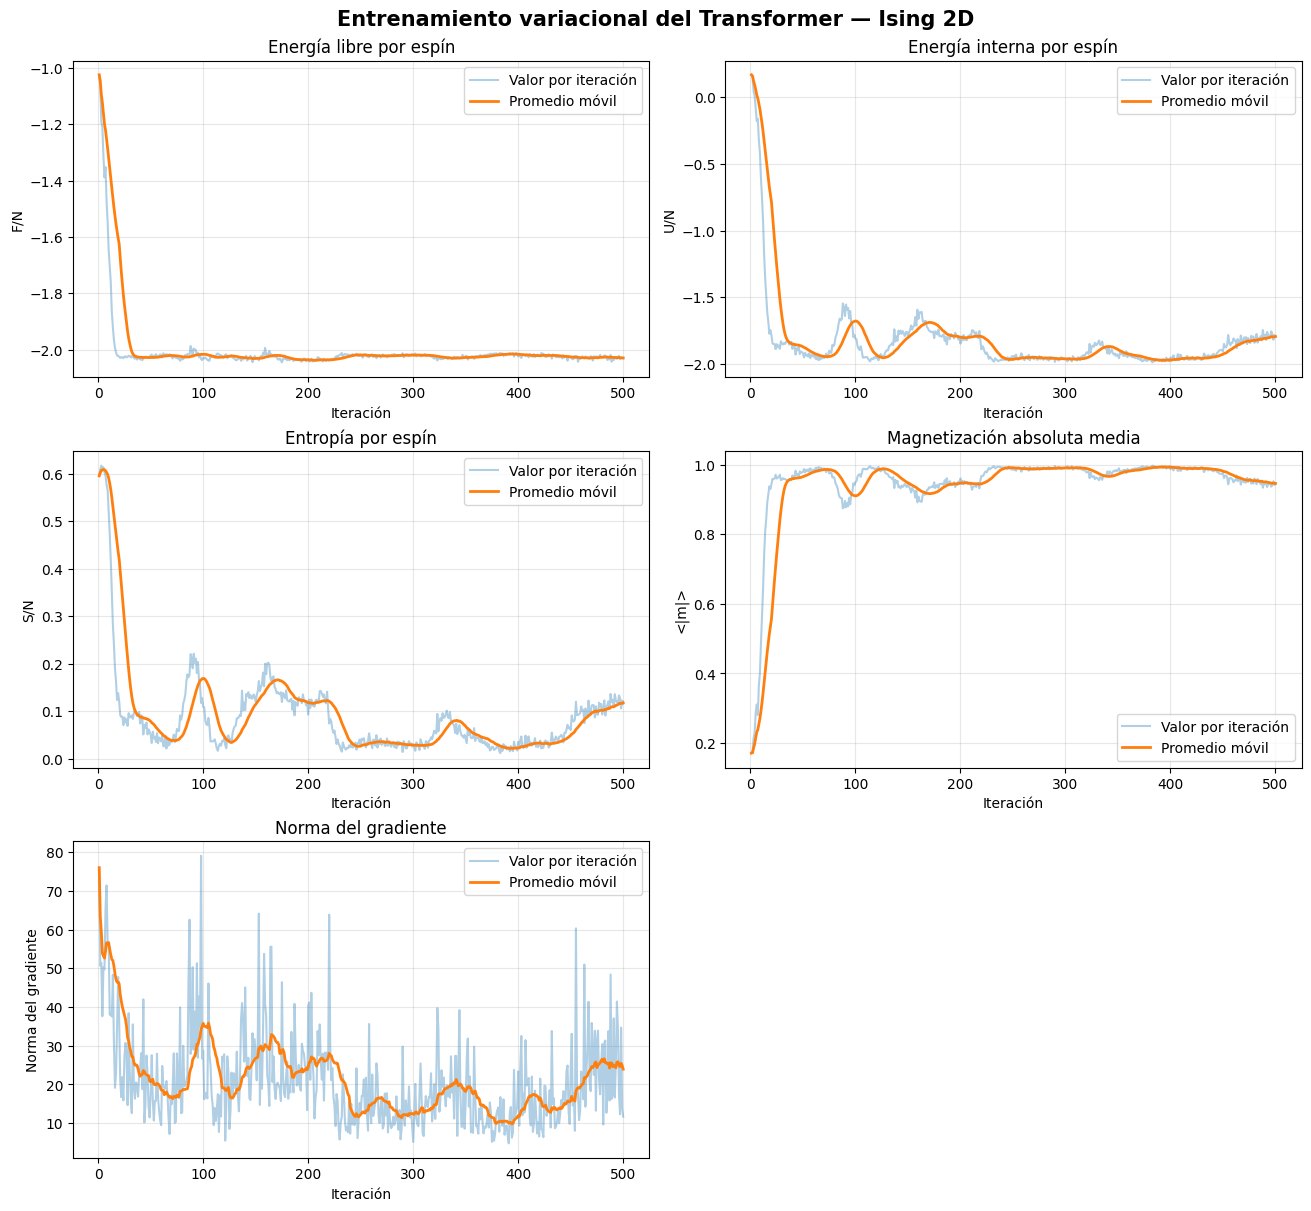

In [ ]:

# ============================================================
# CURVAS DE ENTRENAMIENTO
# ============================================================

import pandas as pd

# Crear tabla con los historiales
historial = pd.DataFrame({
    "Iteracion": np.arange(
        1,
        len(historial_energia_libre) + 1
    ),
    "F_por_espin": historial_energia_libre,
    "U_por_espin": historial_energia,
    "S_por_espin": historial_entropia,
    "Magnetizacion": historial_magnetizacion,
    "Norma_gradiente": historial_gradiente
})

# Promedio móvil
ventana = min(20, len(historial))

columnas = [
    "F_por_espin",
    "U_por_espin",
    "S_por_espin",
    "Magnetizacion",
    "Norma_gradiente"
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(13, 12),
    constrained_layout=True
)

titulos = [
    "Energía libre por espín",
    "Energía interna por espín",
    "Entropía por espín",
    "Magnetización absoluta media",
    "Norma del gradiente"
]

etiquetas = [
    "F/N",
    "U/N",
    "S/N",
    "<|m|>",
    "Norma del gradiente"
]

for i, columna in enumerate(columnas):

    ax = axes.flat[i]

    valores = historial[columna]

    promedio = valores.rolling(
        window=ventana,
        min_periods=1
    ).mean()

    ax.plot(
        historial["Iteracion"],
        valores,
        alpha=0.35,
        label="Valor por iteración"
    )

    ax.plot(
        historial["Iteracion"],
        promedio,
        linewidth=2,
        label="Promedio móvil"
    )

    ax.set_title(titulos[i])
    ax.set_xlabel("Iteración")
    ax.set_ylabel(etiquetas[i])
    ax.grid(alpha=0.3)
    ax.legend()

# Ocultar el último panel vacío
axes.flat[-1].axis("off")

fig.suptitle(
    "Entrenamiento variacional del Transformer — Ising 2D",
    fontsize=15,
    fontweight="bold"
)

plt.show()



### 7.6. Evaluación preliminar del entrenamiento

Después de completar las iteraciones de optimización, realizaremos una primera revisión de los resultados.

Compararemos los valores registrados al comienzo y al final del entrenamiento.

Esta comparación permite identificar cambios en la energía libre, la energía interna, la entropía y la magnetización absoluta media.

Sin embargo, debemos tener presente que los valores de cada iteración se obtienen mediante muestras diferentes y corresponden a distribuciones del Transformer que cambian durante la optimización.

Por esta razón, la comparación entre la primera y la última iteración constituye únicamente un diagnóstico preliminar.

Para evaluar con mayor precisión la calidad de la distribución aprendida, posteriormente generaremos un lote independiente y calcularemos las propiedades termodinámicas correspondientes.

También compararemos los resultados con una enumeración exacta de las configuraciones del modelo de Ising.

Esta última comparación permitirá determinar qué tan cerca se encuentra la distribución aprendida de la distribución de Boltzmann.


In [ ]:

# ============================================================
# RESUMEN PRELIMINAR DEL ENTRENAMIENTO
# ============================================================

resumen = pd.DataFrame({
    "Magnitud": [
        "Energía libre por espín",
        "Energía interna por espín",
        "Entropía por espín",
        "Magnetización absoluta media"
    ],
    "Primera iteración": [
        historial_energia_libre[0],
        historial_energia[0],
        historial_entropia[0],
        historial_magnetizacion[0]
    ],
    "Última iteración": [
        historial_energia_libre[-1],
        historial_energia[-1],
        historial_entropia[-1],
        historial_magnetizacion[-1]
    ]
})

resumen["Cambio"] = (
    resumen["Última iteración"]
    - resumen["Primera iteración"]
)

display(
    resumen.style.format({
        "Primera iteración": "{:.6f}",
        "Última iteración": "{:.6f}",
        "Cambio": "{:+.6f}"
    })
)

print(f"Iteraciones completadas: {len(historial)}")
print(f"Tiempo total: {tiempo_total/60:.2f} minutos")


,Magnitud,Primera iteración,Última iteración,Cambio
0,Energía libre por espín,-1.024787,-2.030727,-1.005940
1,Energía interna por espín,0.166016,-1.798828,-1.964844
2,Entropía por espín,0.595402,0.115950,-0.479452
3,Magnetización absoluta media,0.170898,0.946289,+0.775391


Iteraciones completadas: 500
Tiempo total: 0.55 minutos



### 7.7. Conclusión del séptimo paso

En esta etapa se integraron los componentes desarrollados anteriormente para implementar el entrenamiento variacional del Transformer autorregresivo.

En cada iteración se generó un nuevo lote de configuraciones del modelo de Ising, se calcularon sus energías y logaritmos de probabilidad, y se estimaron las magnitudes termodinámicas correspondientes.

La actualización de los parámetros se realizó mediante el optimizador Adam y el gradiente de la función auxiliar:

$$
\mathcal L_{\mathrm{aux}}
=
\frac{1}{M}\sum_{m=1}^{M}
\operatorname{stopgrad}(E_m+T\ell_m)\ell_m.
$$

También se registró la evolución de la energía libre por espín, la energía interna, la entropía, la magnetización absoluta media y la norma del gradiente.

Las curvas obtenidas permiten estudiar el comportamiento del procedimiento de optimización y evaluar preliminarmente su estabilidad.

No obstante, la disminución de la energía libre estimada durante el entrenamiento no constituye por sí sola una demostración de que el Transformer haya reproducido correctamente la distribución de Boltzmann.

Para establecer la calidad de la aproximación será necesario realizar una evaluación independiente y comparar las propiedades físicas del modelo entrenado con los resultados exactos del sistema de Ising.

Esta comparación se desarrollará en el siguiente paso.



## 8. Evaluación del Transformer y comparación con la solución exacta

### 8.1. Objetivo de la validación

Después de entrenar el Transformer autorregresivo, necesitamos determinar qué tan bien aproxima la distribución de equilibrio del modelo de Ising.

La distribución de Boltzmann está definida por:

$$
\boxed{
p_B(s)=\frac{e^{-E(s)/T}}{Z}
}
$$

donde la función de partición es:

$$
\boxed{
Z=\sum_s e^{-E(s)/T}.
}
$$

En general, calcular esta suma resulta computacionalmente costoso porque el número de configuraciones aumenta exponencialmente con el tamaño del sistema:

$$
\Omega=2^N=2^{L^2}.
$$

Sin embargo, para una red pequeña de $4\times4$ tenemos:

$$
\Omega=2^{16}=65536.
$$

Este número permite enumerar todas las configuraciones posibles y obtener resultados exactos para el sistema finito.

La energía libre exacta de equilibrio es:

$$
\boxed{
F_B=-T\ln Z.
}
$$

De acuerdo con el principio variacional de Gibbs:

$$
F[q_\theta]\geq F_B.
$$

La igualdad se alcanza únicamente cuando la distribución del Transformer coincide con la distribución de Boltzmann.

En esta etapa compararemos las propiedades termodinámicas obtenidas por el Transformer con los resultados exactos.

Además, aprovecharemos la enumeración completa para verificar directamente la normalización de la distribución aprendida y calcular la divergencia de Kullback-Leibler.

Esta comparación nos permitirá evaluar la calidad física y estadística del entrenamiento.


In [ ]:

# ============================================================
# PASO 8: ENUMERACIÓN EXACTA DE CONFIGURACIONES
# ============================================================

import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

# Número total de configuraciones
numero_configuraciones = 2**N

# Enteros de 0 a 2^N - 1
indices = torch.arange(
    numero_configuraciones,
    dtype=torch.long,
    device=device
)

# Posiciones de los bits
posiciones_bits = torch.arange(
    N - 1,
    -1,
    -1,
    dtype=torch.long,
    device=device
)

# Representación binaria
bits = (
    (indices[:, None] >> posiciones_bits[None, :]) & 1
)

# Conversión de bits {0,1} a espines {-1,+1}
configuraciones_exactas = 2 * bits - 1

print("ENUMERACIÓN EXACTA")
print("-" * 55)

print("Número total de configuraciones:", numero_configuraciones)
print("Dimensiones:", configuraciones_exactas.shape)

print("\nPrimera configuración:")
print(configuraciones_exactas[0].reshape(L, L).cpu().numpy())

print("\nÚltima configuración:")
print(configuraciones_exactas[-1].reshape(L, L).cpu().numpy())

# Verificaciones
assert configuraciones_exactas.shape == (
    numero_configuraciones, N
)

assert torch.unique(
    configuraciones_exactas,
    dim=0
).shape[0] == numero_configuraciones

print("\nEnumeración verificada correctamente.")


ENUMERACIÓN EXACTA
-------------------------------------------------------
Número total de configuraciones: 65536
Dimensiones: torch.Size([65536, 16])

Primera configuración:
[[-1 -1 -1 -1]
 [-1 -1 -1 -1]
 [-1 -1 -1 -1]
 [-1 -1 -1 -1]]

Última configuración:
[[1 1 1 1]
 [1 1 1 1]
 [1 1 1 1]
 [1 1 1 1]]

Enumeración verificada correctamente.



### 8.2. Cálculo exacto de la función de partición

La función de partición del modelo de Ising es:

$$
Z=\sum_s e^{-\beta E(s)},
$$

donde:

$$
\beta=\frac{1}{T}
$$

porque utilizamos unidades con $k_B=1$.

Una vez enumeradas todas las configuraciones, podemos calcular la energía de cada una mediante el Hamiltoniano implementado anteriormente.

Después evaluamos:

$$
Z=\sum_{m=1}^{2^N}e^{-\beta E_m}.
$$

Sin embargo, calcular directamente las exponenciales puede generar problemas de precisión numérica cuando las energías o el tamaño del sistema aumentan.

Para evitarlo, utilizaremos la operación `logsumexp`, que permite calcular el logaritmo de una suma de exponenciales de forma numéricamente estable.

Definimos:

$$
a_m=-\beta E_m.
$$

Entonces:

$$
\boxed{
\ln Z=\operatorname{logsumexp}(a_1,\ldots,a_{2^N}).
}
$$

Finalmente:

$$
\boxed{
F_B=-T\ln Z.
}
$$

También calcularemos la energía libre exacta por espín:

$$
f_B=\frac{F_B}{N}.
$$

Este valor será nuestra principal referencia para evaluar el entrenamiento variacional.


In [ ]:

# ============================================================
# FUNCIÓN DE PARTICIÓN Y ENERGÍA LIBRE EXACTA
# ============================================================

# Calcular las energías de todas las configuraciones
energias_exactas = energia_ising(
    configuraciones_exactas,
    L=L,
    J=J,
    h=h
).to(torch.float64)

# Inversa de la temperatura
beta = 1.0 / T

# Logaritmos de los pesos de Boltzmann
log_pesos = -beta * energias_exactas

# Función de partición en escala logarítmica
log_Z = torch.logsumexp(
    log_pesos,
    dim=0
)

# Función de partición
Z_exacto = torch.exp(log_Z)

# Energía libre exacta
F_B = -T * log_Z

# Energía libre por espín
f_B = F_B / N

print("SOLUCIÓN EXACTA DEL MODELO DE ISING")
print("-" * 55)

print(f"Temperatura: {T:.4f}")
print(f"Logaritmo de Z: {log_Z.item():.8f}")
print(f"Función de partición Z: {Z_exacto.item():.8e}")

print(f"\nEnergía libre exacta F_B: {F_B.item():.8f}")
print(f"Energía libre exacta por espín: {f_B.item():.8f}")


SOLUCIÓN EXACTA DEL MODELO DE ISING
-------------------------------------------------------
Temperatura: 2.0000
Logaritmo de Z: 17.10536712
Función de partición Z: 2.68390136e+07

Energía libre exacta F_B: -34.21073424
Energía libre exacta por espín: -2.13817089



### 8.3. Energía interna y magnetización exactas

Una vez calculada la función de partición, podemos obtener las probabilidades exactas:

$$
p_B(s)=\frac{e^{-\beta E(s)}}{Z}.
$$

Estas probabilidades permiten calcular los valores esperados de cualquier observable del sistema.

La energía interna exacta está dada por:

$$
\boxed{
U_B=\sum_s p_B(s)E(s).
}
$$

La energía interna por espín es:

$$
u_B=\frac{U_B}{N}.
$$

Para cada configuración definimos la magnetización por espín:

$$
m(s)=\frac{1}{N}\sum_{i=1}^{N}s_i.
$$

Como el campo externo es cero, el Hamiltoniano es invariante bajo la inversión global de todos los espines:

$$
s_i\longrightarrow -s_i.
$$

Por esta simetría, la magnetización media exacta de un sistema finito es:

$$
\langle m\rangle_B=0.
$$

Sin embargo, esto no significa que las configuraciones carezcan de orden magnético.

Por esta razón, utilizaremos la magnetización absoluta media:

$$
\boxed{
\langle |m|\rangle_B
=
\sum_s p_B(s)|m(s)|.
}
$$

También calcularemos la entropía exacta a partir de:

$$
\boxed{
S_B=\frac{U_B-F_B}{T}.
}
$$

Estas magnitudes proporcionarán las referencias físicas necesarias para evaluar el Transformer entrenado.


In [ ]:

# ============================================================
# OBSERVABLES TERMODINÁMICOS EXACTOS
# ============================================================

# Probabilidades exactas de Boltzmann
p_B = torch.exp(
    log_pesos - log_Z
)

# Energía interna exacta
U_B = torch.sum(
    p_B * energias_exactas
)

# Energía interna por espín
u_B = U_B / N

# Magnetización por espín de cada configuración
magnetizaciones_exactas = (
    configuraciones_exactas.to(torch.float64).mean(dim=1)
)

# Magnetización media
m_B = torch.sum(
    p_B * magnetizaciones_exactas
)

# Magnetización absoluta media
m_abs_B = torch.sum(
    p_B * magnetizaciones_exactas.abs()
)

# Entropía exacta
S_B = (U_B - F_B) / T

# Entropía por espín
s_B = S_B / N

print("OBSERVABLES EXACTOS")
print("-" * 55)

print(f"Energía interna U_B: {U_B.item():.8f}")
print(f"Energía por espín: {u_B.item():.8f}")

print(f"\nEntropía S_B: {S_B.item():.8f}")
print(f"Entropía por espín: {s_B.item():.8f}")

print(f"\nMagnetización media: {m_B.item():.8f}")
print(f"Magnetización absoluta media: {m_abs_B.item():.8f}")

print(f"\nSuma de probabilidades: {p_B.sum().item():.12f}")

assert torch.allclose(
    p_B.sum(),
    torch.tensor(1.0, dtype=torch.float64, device=device),
    atol=1e-10
)

print("\nDistribución de Boltzmann normalizada.")


OBSERVABLES EXACTOS
-------------------------------------------------------
Energía interna U_B: -28.08608462
Energía por espín: -1.75538029

Entropía S_B: 3.06232481
Entropía por espín: 0.19139530

Magnetización media: 0.00000000
Magnetización absoluta media: 0.91894327

Suma de probabilidades: 1.000000000000

Distribución de Boltzmann normalizada.



### 8.4. Evaluación independiente del Transformer entrenado

Después de completar el entrenamiento, debemos evaluar el modelo utilizando configuraciones nuevas.

Esto es importante porque los lotes utilizados durante la optimización contienen fluctuaciones estadísticas y fueron generados por distribuciones que cambiaban continuamente.

Para obtener una evaluación independiente, generaremos un lote adicional de configuraciones utilizando los parámetros finales del Transformer.

Denotaremos el tamaño de este lote por:

$$
M_{\mathrm{eval}}.
$$

A partir de las nuevas configuraciones calcularemos:

$$
\widehat U_\theta
=
\frac{1}{M_{\mathrm{eval}}}
\sum_m E_m,
$$

$$
\widehat S_\theta
=
-\frac{1}{M_{\mathrm{eval}}}
\sum_m\ln q_\theta(s^{(m)}),
$$

y

$$
\boxed{
\widehat F_\theta
=
\widehat U_\theta-T\widehat S_\theta.
}
$$

También calcularemos la magnetización absoluta media:

$$
\widehat{\langle |m|\rangle}_\theta
=
\frac{1}{M_{\mathrm{eval}}}
\sum_m |m(s^{(m)})|.
$$

Utilizaremos un lote mayor que el empleado durante el entrenamiento para reducir las fluctuaciones estadísticas de las estimaciones.

La comparación con los valores exactos permitirá determinar si el modelo ha aprendido correctamente las propiedades termodinámicas del sistema.


In [ ]:

# ============================================================
# EVALUACIÓN INDEPENDIENTE DEL TRANSFORMER
# ============================================================

modelo.eval()

M_eval = 4096
tamano_bloque = 128

configuraciones_evaluacion = []

# Generar muestras en bloques
for inicio in range(0, M_eval, tamano_bloque):

    cantidad = min(
        tamano_bloque,
        M_eval - inicio
    )

    muestras = generar_configuraciones(
        modelo,
        M=cantidad,
        N=N,
        device=device
    )

    configuraciones_evaluacion.append(muestras)

# Unir los bloques
configuraciones_evaluacion = torch.cat(
    configuraciones_evaluacion,
    dim=0
)

# Calcular observables
with torch.no_grad():

    E_eval = energia_ising(
        configuraciones_evaluacion,
        L=L,
        J=J,
        h=h
    ).to(torch.float64)

    log_q_eval = log_probabilidad(
        modelo,
        configuraciones_evaluacion
    ).to(torch.float64)

    U_eval = E_eval.mean()

    S_eval = -log_q_eval.mean()

    F_eval = U_eval - T * S_eval

    m_abs_eval = (
        configuraciones_evaluacion
        .to(torch.float64)
        .mean(dim=1)
        .abs()
        .mean()
    )

print("EVALUACIÓN INDEPENDIENTE")
print("-" * 55)

print(f"Configuraciones evaluadas: {M_eval}")

print(f"\nEnergía libre por espín: {(F_eval/N).item():.8f}")
print(f"Energía interna por espín: {(U_eval/N).item():.8f}")
print(f"Entropía por espín: {(S_eval/N).item():.8f}")
print(f"Magnetización absoluta: {m_abs_eval.item():.8f}")


EVALUACIÓN INDEPENDIENTE
-------------------------------------------------------
Configuraciones evaluadas: 4096

Energía libre por espín: -2.03118331
Energía interna por espín: -1.79724121
Entropía por espín: 0.11697105
Magnetización absoluta: 0.94668579



### 8.5. Comparación entre el Transformer y la solución exacta

Para evaluar la calidad del entrenamiento compararemos los observables termodinámicos del Transformer con los resultados exactos del modelo de Ising.

Consideraremos las siguientes magnitudes:

$$
f=\frac{F}{N},
\qquad
u=\frac{U}{N},
\qquad
s=\frac{S}{N},
\qquad
\langle |m|\rangle.
$$

Para cada observable calcularemos el error absoluto:

$$
\boxed{
\varepsilon_A=
|A_{\mathrm{Transformer}}-A_{\mathrm{exacto}}|.
}
$$

Un error pequeño indica que el Transformer reproduce adecuadamente ese observable.

Sin embargo, la coincidencia de algunos valores esperados no garantiza necesariamente que la distribución completa haya sido aprendida.

Por esta razón, además de comparar las magnitudes termodinámicas, calcularemos posteriormente la divergencia de Kullback-Leibler.

La comparación de observables constituye una primera evaluación física, mientras que la divergencia permite estudiar directamente la diferencia entre las distribuciones de probabilidad.


In [ ]:

# ============================================================
# COMPARACIÓN TRANSFORMER VS SOLUCIÓN EXACTA
# ============================================================

magnitudes = [
    "Energía libre por espín",
    "Energía interna por espín",
    "Entropía por espín",
    "Magnetización absoluta media"
]

valores_exactos = np.array([
    f_B.item(),
    u_B.item(),
    s_B.item(),
    m_abs_B.item()
])

valores_transformer = np.array([
    (F_eval / N).item(),
    (U_eval / N).item(),
    (S_eval / N).item(),
    m_abs_eval.item()
])

errores_absolutos = np.abs(
    valores_transformer - valores_exactos
)

comparacion = pd.DataFrame({
    "Magnitud": magnitudes,
    "Valor exacto": valores_exactos,
    "Transformer": valores_transformer,
    "Error absoluto": errores_absolutos
})

display(
    comparacion.style.format({
        "Valor exacto": "{:.6f}",
        "Transformer": "{:.6f}",
        "Error absoluto": "{:.6f}"
    })
)


,Magnitud,Valor exacto,Transformer,Error absoluto
0,Energía libre por espín,-2.138171,-2.031183,0.106988
1,Energía interna por espín,-1.755380,-1.797241,0.041861
2,Entropía por espín,0.191395,0.116971,0.074424
3,Magnetización absoluta media,0.918943,0.946686,0.027743



### 8.6. Verificación de la normalización de $q_\theta(s)$

La distribución del Transformer está definida mediante la factorización autorregresiva:

$$
q_\theta(s)
=
\prod_{i=1}^{N}
q_\theta(s_i\mid s_{<i}).
$$

Como cada distribución condicional está normalizada, la distribución conjunta también debe satisfacer:

$$
\boxed{
\sum_s q_\theta(s)=1.
}
$$

En el paso 1 verificamos que las probabilidades condicionales producidas por softmax sumaban uno.

Ahora realizaremos una comprobación más completa.

Como trabajamos con una red de 16 espines, podemos enumerar las 65536 configuraciones posibles y calcular directamente la probabilidad que el Transformer asigna a cada una.

Después sumaremos estas probabilidades:

$$
Z_q=\sum_s q_\theta(s).
$$

El resultado esperado es:

$$
Z_q\approx1.
$$

Para evitar problemas de memoria, evaluaremos las configuraciones en bloques.

También utilizaremos precisión doble al acumular las probabilidades.

Esta comprobación es importante porque verifica numéricamente la consistencia de la distribución conjunta implementada.


In [ ]:

# ============================================================
# DISTRIBUCIÓN EXACTA DEL TRANSFORMER
# ============================================================

modelo.eval()

tamano_bloque_exacto = 512

log_q_exacta_bloques = []

with torch.no_grad():

    for inicio in range(
        0,
        numero_configuraciones,
        tamano_bloque_exacto
    ):

        bloque = configuraciones_exactas[
            inicio:inicio + tamano_bloque_exacto
        ]

        log_q_bloque = log_probabilidad(
            modelo,
            bloque
        )

        log_q_exacta_bloques.append(
            log_q_bloque.detach().cpu().to(torch.float64)
        )

# Log-probabilidades de todas las configuraciones
log_q_exacta = torch.cat(
    log_q_exacta_bloques,
    dim=0
)

# Probabilidades
q_exacta = torch.exp(log_q_exacta)

# Suma de probabilidades
normalizacion_q = q_exacta.sum()

print("NORMALIZACIÓN DEL TRANSFORMER")
print("-" * 55)

print(f"Configuraciones evaluadas: {len(q_exacta)}")

print(f"Suma de probabilidades: {normalizacion_q.item():.12f}")

print(
    "Error de normalización:",
    f"{abs(normalizacion_q.item()-1):.3e}"
)

assert torch.isclose(
    normalizacion_q,
    torch.tensor(1.0, dtype=torch.float64),
    atol=1e-5
)

print("\nLa distribución conjunta está normalizada.")


NORMALIZACIÓN DEL TRANSFORMER
-------------------------------------------------------
Configuraciones evaluadas: 65536
Suma de probabilidades: 0.999999710578
Error de normalización: 2.894e-07

La distribución conjunta está normalizada.



### 8.7. Divergencia de Kullback-Leibler

La comparación más importante de este reto consiste en cuantificar la diferencia entre la distribución aprendida por el Transformer y la distribución de Boltzmann.

Para ello utilizaremos la divergencia de Kullback-Leibler:

$$
\boxed{
D_{\mathrm{KL}}(q_\theta\|p_B)
=
\sum_s q_\theta(s)
\ln\frac{q_\theta(s)}{p_B(s)}.
}
$$

Esta cantidad satisface:

$$
D_{\mathrm{KL}}(q_\theta\|p_B)\geq0.
$$

La igualdad ocurre cuando:

$$
q_\theta(s)=p_B(s)
$$

para todas las configuraciones.

Como:

$$
\ln p_B(s)=-\frac{E(s)}{T}-\ln Z,
$$

sustituimos en la divergencia:

$$
D_{\mathrm{KL}}
=
\sum_s q_\theta(s)
\left[
\ln q_\theta(s)
+\frac{E(s)}{T}
+\ln Z
\right].
$$

Separando términos:

$$
D_{\mathrm{KL}}
=
\sum_s q_\theta(s)\ln q_\theta(s)
+
\frac{1}{T}\sum_s q_\theta(s)E(s)
+
\ln Z.
$$

Recordando que:

$$
F[q_\theta]
=
\sum_s q_\theta(s)
\left[E(s)+T\ln q_\theta(s)\right],
$$

obtenemos:

$$
D_{\mathrm{KL}}
=
\frac{F[q_\theta]}{T}+\ln Z.
$$

Finalmente, como:

$$
F_B=-T\ln Z,
$$

resulta:

$$
\boxed{
D_{\mathrm{KL}}(q_\theta\|p_B)
=
\frac{F[q_\theta]-F_B}{T}.
}
$$

Esta identidad conecta directamente la optimización variacional con la teoría de la información.

Minimizar la energía libre variacional equivale a minimizar la divergencia de Kullback-Leibler respecto a la distribución de Boltzmann.

Para nuestra red pequeña podremos calcular la divergencia directamente, utilizando todas las configuraciones posibles.


In [ ]:

# ============================================================
# DIVERGENCIA KL EXACTA
# ============================================================

# Llevar las energías y probabilidades al mismo dispositivo
E_todas = energias_exactas.detach().cpu()
log_p_B = (log_pesos - log_Z).detach().cpu()

# Energía interna exacta de la distribución del Transformer
U_q_exacto = torch.sum(
    q_exacta * E_todas
)

# Entropía exacta de la distribución del Transformer
S_q_exacto = -torch.sum(
    q_exacta * log_q_exacta
)

# Energía libre exacta de q_theta
F_q_exacto = U_q_exacto - T * S_q_exacto

# Divergencia KL calculada directamente
KL_directa = torch.sum(
    q_exacta * (log_q_exacta - log_p_B)
)

# Divergencia KL a partir de las energías libres
KL_energia_libre = (
    F_q_exacto - F_B.detach().cpu()
) / T

print("DIVERGENCIA DE KULLBACK-LEIBLER")
print("-" * 60)

print(f"F[q_theta] exacta: {F_q_exacto.item():.8f}")

print(f"F_B exacta: {(F_B.item()):.8f}")

print(f"\nKL calculada directamente: {KL_directa.item():.10f}")

print(f"KL mediante energía libre: {KL_energia_libre.item():.10f}")

print(
    "\nDiferencia entre expresiones:",
    f"{abs(KL_directa.item()-KL_energia_libre.item()):.3e}"
)

assert torch.allclose(
    KL_directa,
    KL_energia_libre,
    atol=1e-5,
    rtol=1e-5
)

print("\nIdentidad variacional verificada.")


DIVERGENCIA DE KULLBACK-LEIBLER
------------------------------------------------------------
F[q_theta] exacta: -32.51093653
F_B exacta: -34.21073424

KL calculada directamente: 0.8498939023
KL mediante energía libre: 0.8498988530

Diferencia entre expresiones: 4.951e-06

Identidad variacional verificada.



### 8.8. Comparación de las distribuciones energéticas

Además de comparar valores esperados, podemos estudiar cómo se distribuyen las probabilidades entre los diferentes niveles de energía del sistema.

Para cada valor de energía $E$, definimos:

$$
P_B(E)=\sum_{s:E(s)=E}p_B(s)
$$

y

$$
P_\theta(E)=\sum_{s:E(s)=E}q_\theta(s).
$$

Estas expresiones representan la probabilidad total de encontrar una configuración con energía $E$.

La comparación es interesante porque diferentes configuraciones pueden tener la misma energía.

Si el Transformer ha aprendido correctamente la distribución de equilibrio, esperamos que:

$$
P_\theta(E)\approx P_B(E).
$$

Sin embargo, una coincidencia entre las distribuciones de energía no garantiza por sí sola que las probabilidades de todas las configuraciones individuales coincidan.

Por esta razón, esta comparación complementa, pero no reemplaza, el cálculo de la divergencia de Kullback-Leibler.


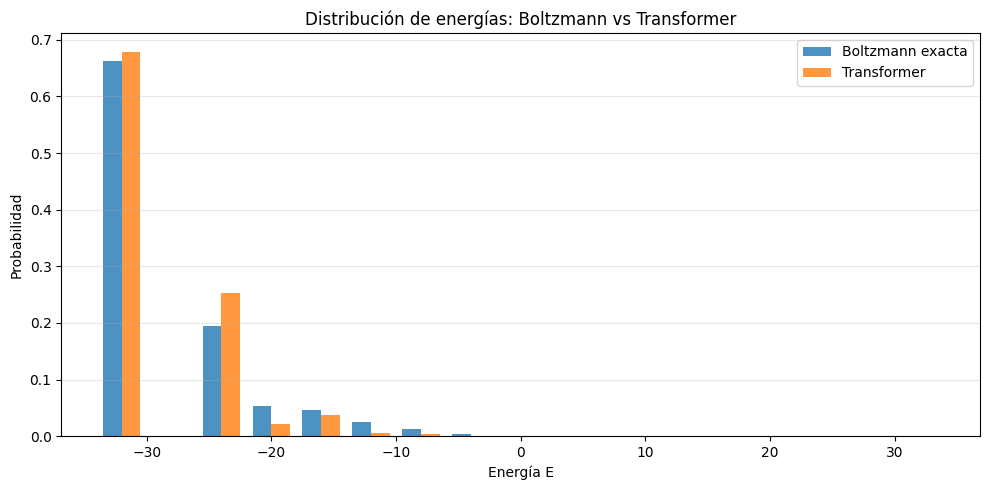

In [ ]:

# ============================================================
# DISTRIBUCIONES DE ENERGÍA
# ============================================================

# Preparar arreglos
E_numpy = energias_exactas.detach().cpu().numpy()

p_B_numpy = p_B.detach().cpu().numpy()
q_numpy = q_exacta.detach().cpu().numpy()

# Valores de energía diferentes
niveles_energia = np.unique(E_numpy)

P_B_E = np.array([
    p_B_numpy[E_numpy == E].sum()
    for E in niveles_energia
])

P_q_E = np.array([
    q_numpy[E_numpy == E].sum()
    for E in niveles_energia
])

# Graficar
plt.figure(figsize=(10, 5))

ancho = 1.5

plt.bar(
    niveles_energia - ancho / 2,
    P_B_E,
    width=ancho,
    label="Boltzmann exacta",
    alpha=0.8
)

plt.bar(
    niveles_energia + ancho / 2,
    P_q_E,
    width=ancho,
    label="Transformer",
    alpha=0.8
)

plt.xlabel("Energía E")
plt.ylabel("Probabilidad")
plt.title(
    "Distribución de energías: Boltzmann vs Transformer"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



### 8.9. Conclusión de la evaluación

En esta etapa se desarrolló una validación física y estadística del Transformer autorregresivo entrenado para el modelo de Ising bidimensional.

Mediante enumeración completa de las configuraciones de una red de $4\times4$, se calculó la función de partición exacta y se obtuvo la energía libre de equilibrio:

$$
F_B=-T\ln Z.
$$

También se determinaron la energía interna, la entropía y la magnetización absoluta media de la distribución de Boltzmann.

Posteriormente, se realizó una evaluación independiente del Transformer utilizando configuraciones nuevas y se compararon sus propiedades termodinámicas con los resultados exactos.

Además, se evaluó la probabilidad asignada por el Transformer a todas las configuraciones posibles, permitiendo verificar directamente la normalización de la distribución conjunta.

Finalmente, se calculó la divergencia de Kullback-Leibler:

$$
D_{\mathrm{KL}}(q_\theta\|p_B)
=
\frac{F[q_\theta]-F_B}{T}.
$$

Esta identidad proporciona una conexión entre el principio variacional de Gibbs y la diferencia entre distribuciones de probabilidad.

El procedimiento desarrollado permite evaluar cuantitativamente la calidad de la aproximación obtenida mediante el Transformer.

La conclusión sobre la precisión del modelo deberá basarse en los resultados numéricos observados, especialmente en la diferencia de energía libre, la divergencia KL y la comparación de los observables termodinámicos.

En conjunto, el reto muestra cómo un modelo generativo autorregresivo puede utilizarse para aproximar distribuciones de equilibrio de sistemas físicos mediante una formulación variacional basada en principios de mecánica estadística.


In [ ]:

# ============================================================
# TABLA FINAL DE VALIDACIÓN DEL RETO
# ============================================================

# Magnetización absoluta exacta bajo q_theta
m_abs_q_exacto = torch.sum(
    q_exacta
    * magnetizaciones_exactas.detach().cpu().abs()
)

tabla_final = pd.DataFrame({
    "Magnitud": [
        "Energía libre por espín",
        "Energía interna por espín",
        "Entropía por espín",
        "Magnetización absoluta media"
    ],
    "Boltzmann exacta": [
        f_B.item(),
        u_B.item(),
        s_B.item(),
        m_abs_B.item()
    ],
    "Transformer (enumeración)": [
        (F_q_exacto / N).item(),
        (U_q_exacto / N).item(),
        (S_q_exacto / N).item(),
        m_abs_q_exacto.item()
    ]
})

tabla_final["Error absoluto"] = (
    tabla_final["Transformer (enumeración)"]
    - tabla_final["Boltzmann exacta"]
).abs()

display(
    tabla_final.style.format({
        "Boltzmann exacta": "{:.8f}",
        "Transformer (enumeración)": "{:.8f}",
        "Error absoluto": "{:.8f}"
    })
)

print("\nINDICADORES FINALES")
print("-" * 55)

print(f"Temperatura: {T}")
print(f"Tamaño de red: {L} x {L}")
print(f"Configuraciones exactas: {2**N}")

print(f"\nNormalización de q: {normalizacion_q.item():.10f}")

print(f"Divergencia KL: {KL_directa.item():.10f}")

print(
    "Diferencia de energía libre:",
    f"{(F_q_exacto - F_B.detach().cpu()).item():.10f}"
)

print("\nEvaluación final completada.")


,Magnitud,Boltzmann exacta,Transformer (enumeración),Error absoluto
0,Energía libre por espín,-2.13817089,-2.03193353,0.10623736
1,Energía interna por espín,-1.75538029,-1.80704270,0.05166242
2,Entropía por espín,0.19139530,0.11244541,0.07894989
3,Magnetización absoluta media,0.91894327,0.94947509,0.03053182



INDICADORES FINALES
-------------------------------------------------------
Temperatura: 2.0
Tamaño de red: 4 x 4
Configuraciones exactas: 65536

Normalización de q: 0.9999997106
Divergencia KL: 0.8498939023
Diferencia de energía libre: 1.6997977060

Evaluación final completada.



## 9. Análisis de resultados y conclusiones

### 9.1. Análisis del entrenamiento variacional

En este trabajo implementamos un Transformer autorregresivo para aproximar la distribución de Boltzmann del modelo de Ising bidimensional, utilizando el principio variacional de Gibbs como fundamento del entrenamiento.

Trabajamos con una red de $4\times4$ espines, interacción ferromagnética $J=1$, campo externo $h=0$ y temperatura $T=2.0$. El entrenamiento se realizó durante 500 iteraciones mediante el optimizador Adam y un estimador de gradiente basado en la función de puntuación.

Al observar las curvas de entrenamiento, encontramos que la energía libre por espín disminuyó rápidamente durante las primeras iteraciones, pasando de valores cercanos a $-1.0$ hasta aproximadamente $-2.0$. Esto indica que el Transformer modificó su distribución inicial y comenzó a favorecer configuraciones con menor energía libre.

Después de esta disminución inicial, la energía libre presentó oscilaciones relativamente pequeñas alrededor de $-2.0$. Aunque esto sugiere cierta estabilización del entrenamiento, no significa que el modelo haya alcanzado el equilibrio exacto, ya que la energía libre de Boltzmann calculada mediante enumeración es más baja.

La energía interna por espín también disminuyó considerablemente, alcanzando valores próximos a $-2.0$ en algunas etapas. Este comportamiento es consistente con el carácter ferromagnético del Hamiltoniano, que favorece las configuraciones en las cuales los espines vecinos se encuentran alineados.

Por otra parte, la entropía por espín disminuyó desde valores iniciales cercanos a $0.6$ hasta valores mucho menores. Esto indica que el Transformer pasó de una distribución relativamente dispersa a otra más concentrada en un conjunto reducido de configuraciones.

La magnetización absoluta media aumentó rápidamente y permaneció durante buena parte del entrenamiento cerca de la unidad. Este resultado muestra que las configuraciones generadas adquirieron un alto grado de orden magnético.

Finalmente, la norma del gradiente presentó fluctuaciones y algunos picos importantes durante el entrenamiento. Esto evidencia que la optimización mantuvo un comportamiento estocástico y que los parámetros continuaron experimentando actualizaciones significativas, incluso después de la disminución inicial de la energía libre.

En conjunto, las curvas muestran que el Transformer aprendió características físicas importantes del sistema, aunque también sugieren que el entrenamiento favoreció una distribución excesivamente concentrada en configuraciones de baja energía.

### 9.2. Comparación con la solución exacta

Para evaluar la precisión del modelo, realizamos una enumeración completa de las $2^{16}=65536$ configuraciones posibles y calculamos las propiedades termodinámicas exactas.

Los resultados obtenidos fueron:

| Magnitud | Boltzmann exacta | Transformer | Error absoluto |
|---|---:|---:|---:|
| Energía libre por espín | -2.138171 | -2.031934 | 0.106237 |
| Energía interna por espín | -1.755380 | -1.807043 | 0.051662 |
| Entropía por espín | 0.191395 | 0.112445 | 0.078950 |
| Magnetización absoluta media | 0.918943 | 0.949475 | 0.030532 |

La energía libre por espín obtenida mediante el Transformer fue de aproximadamente $-2.031934$, mientras que el valor exacto fue $-2.138171$.

La diferencia entre ambos resultados fue:

$$
\Delta f
=
f_\theta-f_B
=
0.106237.
$$

Este resultado es consistente con el principio variacional de Gibbs:

$$
F[q_\theta]\geq F_B.
$$

Es decir, la energía libre de la distribución aprendida permanece por encima de la energía libre exacta de equilibrio.

En cuanto a la energía interna, el Transformer obtuvo un valor ligeramente más negativo que el exacto. Esto significa que su distribución favorece, en promedio, configuraciones más alineadas que las que corresponden al equilibrio térmico a $T=2.0$.

La diferencia más importante desde el punto de vista físico aparece en la entropía. El valor exacto por espín fue aproximadamente $0.191395$, mientras que el Transformer obtuvo $0.112445$.

Esta subestimación indica que la distribución aprendida presenta menos diversidad estadística que la distribución de Boltzmann.

La magnetización absoluta media también fue ligeramente superior a la exacta:

$$
\langle |m|\rangle_\theta
\approx 0.949475,
$$

frente a:

$$
\langle |m|\rangle_B
\approx 0.918943.
$$

Este resultado confirma que el Transformer asigna un peso excesivo a configuraciones altamente magnetizadas.

### 9.3. Interpretación de la distribución de energías

La comparación gráfica entre las distribuciones energéticas del Transformer y de Boltzmann muestra que ambas concentran gran parte de su probabilidad en los niveles de energía más bajos.

En particular, el Transformer reproduce el predominio de las configuraciones cercanas al estado fundamental ferromagnético, cuya energía es:

$$
E_{\min}=-2JN=-32.
$$

Sin embargo, observamos diferencias en la distribución de probabilidades entre los niveles energéticos.

El Transformer asigna una probabilidad ligeramente superior al nivel de energía fundamental y también presenta un exceso de probabilidad en algunos niveles bajos excitados, mientras que subestima otros niveles de energía intermedios.

Esto indica que el modelo aprendió correctamente la tendencia general hacia el orden ferromagnético, pero todavía no reproduce con precisión todos los pesos estadísticos de equilibrio.

La diferencia es relevante porque, a temperatura finita, la distribución de Boltzmann no depende únicamente de minimizar la energía, sino también de la contribución entrópica de las configuraciones accesibles.

Por tanto, reproducir el estado fundamental no es suficiente para representar correctamente el equilibrio termodinámico.

### 9.4. Interpretación desde el principio variacional de Gibbs

Uno de los resultados más importantes de este trabajo es la relación entre la energía libre y la divergencia de Kullback-Leibler:

$$
\boxed{
D_{\mathrm{KL}}(q_\theta\|p_B)
=
\frac{F[q_\theta]-F_B}{T}.
}
$$

A partir de la diferencia de energía libre por espín obtenida:

$$
\Delta f=0.106237,
$$

y considerando que:

$$
N=16,\qquad T=2,
$$

obtenemos:

$$
D_{\mathrm{KL}}(q_\theta\|p_B)
=
\frac{N\Delta f}{T}.
$$

Por tanto:

$$
\boxed{
D_{\mathrm{KL}}(q_\theta\|p_B)
\approx 0.849899.
}
$$

Este valor es positivo, como exige la definición de divergencia KL, y muestra que todavía existe una diferencia apreciable entre la distribución aprendida y la distribución de Boltzmann.

La divergencia por espín es aproximadamente:

$$
\frac{D_{\mathrm{KL}}}{N}
\approx 0.053119.
$$

La diferencia de energía libre también puede descomponerse en sus contribuciones energética y entrópica:

$$
f_\theta-f_B
=
(u_\theta-u_B)-T(s_\theta-s_B).
$$

Con nuestros resultados:

$$
u_\theta-u_B\approx-0.051662,
$$

mientras que:

$$
-T(s_\theta-s_B)
\approx+0.157900.
$$

Por tanto:

$$
\Delta f
\approx
-0.051662+0.157900
\approx0.106237.
$$

Esta descomposición permite identificar el origen físico del error variacional.

Aunque el Transformer obtiene una energía interna más baja que la de equilibrio, la reducción excesiva de la entropía produce una penalización mayor en la energía libre.

En otras palabras, el modelo aprendió a favorecer configuraciones energéticamente convenientes, pero no logró conservar toda la diversidad estadística que corresponde a la temperatura considerada.

Este resultado demuestra por qué minimizar únicamente la energía interna no es equivalente a reproducir correctamente la distribución térmica.

### 9.5. Conclusiones generales

El desarrollo de este reto permitió implementar y estudiar un modelo generativo autorregresivo aplicado a un problema de mecánica estadística.

En primer lugar, comprobamos que el Transformer puede representar una distribución de probabilidad sobre configuraciones de espines mediante una factorización autorregresiva y generar muestras compatibles con esa representación.

En segundo lugar, implementamos correctamente el Hamiltoniano de Ising con condiciones periódicas de frontera y utilizamos el principio variacional de Gibbs para construir una función objetivo con significado termodinámico.

En tercer lugar, el entrenamiento mediante el estimador de función de puntuación permitió modificar la distribución inicial del Transformer y favorecer configuraciones de baja energía, produciendo una disminución considerable de la energía libre estimada.

Sin embargo, la comparación exacta mostró que el modelo todavía presenta diferencias respecto a la distribución de Boltzmann. En particular, encontramos una entropía inferior a la exacta y una magnetización absoluta ligeramente superior, lo que evidencia una concentración excesiva de probabilidad en configuraciones altamente ordenadas.

La divergencia de Kullback-Leibler confirmó cuantitativamente que la distribución aprendida todavía no coincide con la distribución de equilibrio.

Por tanto, podemos concluir que **el entrenamiento fue efectivo para aprender la estructura energética general del sistema ferromagnético, pero no alcanzó una reproducción completamente precisa de sus propiedades estadísticas de equilibrio**.

Como posibles mejoras, sería conveniente explorar un mayor número de iteraciones, tasas de aprendizaje más pequeñas, lotes de muestreo más grandes y técnicas de reducción de varianza del estimador de gradiente. Estas modificaciones podrían favorecer una optimización más estable, aunque su efectividad tendría que comprobarse experimentalmente.

Finalmente, este ejercicio permitió comprender una conexión fundamental entre aprendizaje automático y física estadística: entrenar un modelo generativo mediante la minimización de la energía libre variacional equivale a buscar una distribución de probabilidad cercana a la distribución de Boltzmann.

El resultado más importante no fue únicamente generar configuraciones de baja energía, sino comprobar que **el equilibrio térmico requiere reproducir correctamente tanto la contribución energética como la entrópica del sistema**.
